# Can a model write executable bytes directly?

A processor follows small instructions: fetch a number, add another number, jump to a different instruction, or return an answer. Software developers usually describe the work in a programming language. A compiler translates that description into the instruction bytes the processor can run. Testing whether a language model can supply those bytes itself asks how much of that translation it can carry out without the usual software tools.

Someone building a tiny calculation may want to know whether a model understands a processor's instructions well enough to produce a working function. Someone asking for a program they can launch needs more: an operating system must recognise the file and know where its instructions begin. A useful result must identify which of these capabilities was demonstrated and what kind of work the program performs.

Consider this **illustrative example**, separate from the measured tests. A calculation takes two whole numbers, multiplies the first by 37 and the second by 11, and adds 23. With inputs 2 and 3, the answer is 74 + 33 + 23 = 130. A programmer could write that calculation in a familiar language and ask a compiler to translate it.

The complication is that a processor stores a fixed amount of information in each number. With unsigned 64-bit numbers, adding one to 18,446,744,073,709,551,615 wraps back to zero. That wrap can be part of the requested calculation. A program that works for 2 and 3 has not yet shown that it handles the whole numerical interface correctly.

A file-processing tool adds another kind of work. An integer sorter might receive `3 -1 3 0`, recognise four numbers, keep the duplicate 3, and write `-1`, `0`, `3`, `3` in order. It must find where each number begins and ends, store an unknown number of values within its limit, and write digits back out. Someone using that tool needs the complete file handled correctly, including a clear error if a token is invalid.

There are three practical routes to an executable. The model can write C source and let a compiler translate it. It can choose processor instructions using readable names and let an assembler encode those instructions, then let a linker construct the file. Or it can return every executable byte directly. The last route carries the work of encoding instructions and arranging the file itself. Assembly is the name for the readable instruction language.

An executable also contains information for the operating system: where to load the program and which instruction to start with. ELF is the executable file format used here. The model's direct response must include that information as well as the program logic. Converting its hexadecimal text into bytes is the only preparation allowed on that route; no missing header or instruction is added.

The question is how far this works on five small but different tasks: two numerical calculations and three tools with variable-length input. The file tools are an integer sorter, a binary run-length compressor and an account-total summariser. Within each file task, all three routes must satisfy the same input, output and error contract. Hidden inputs check the result; saved usage records show what generation actually cost.
## Study summary

GPT-6.1 Sol produced 9 fully correct first attempts out of nine complete file-processing programs. Each was checked on 128 hidden files with exact expected output bytes and exit status. There were 0 unreadable or unbuildable/unloadable artifacts. Across all five tasks, 15 of fifteen first attempts passed their whole test set, including the six original numerical artifacts. Those original artifacts include four callable functions and two complete executables, so their interfaces are shown separately in the results.

Direct ELF passed 3/3 programs across the three file tasks; among readable artifacts it passed 3/3. NASM + linker passed 3/3 programs across the three file tasks; among readable artifacts it passed 3/3. C + compiler passed 3/3 programs across the three file tasks; among readable artifacts it passed 3/3.

The 1,920 comparisons evaluate fifteen generated programs, with one generation per slot. The numerical artifacts and all three file tasks are at a correctness ceiling: no case separates the routes. One candidate per slot cannot establish a model's general reliability or a stable ranking of workflows. C and assembly use different external assistance from direct bytes, and C may use a runtime library. No execution-speed or compiler-efficiency claim is tested.

The fifteen calls report 109,522 input tokens and 50,189 output tokens, including 38,965 reasoning tokens. Their recorded standard API equivalent is US$0.698073; actual subscription charges are unavailable. All calls have saved usage records. The result supports the task-specific conclusions below, with exact returned artifacts available for inspection.

Excluding unreadable artifacts does not change the observed ordering of the three file-program routes. This is an ordering of these candidates only, with three tasks per route.

## Contents

- [1. Setup and scope](#1-setup-and-scope)
- [2. Data and exact answers](#2-data-and-exact-answers)
- [3. Three ways to supply a program](#3-three-ways-to-supply-a-program)
- [4. From a response to a checked answer](#4-from-a-response-to-a-checked-answer)
- [5. Correctness across tasks](#5-correctness-across-tasks)
- [6. Token usage and cost](#6-token-usage-and-cost)
- [7. Boundary cases and errors](#7-boundary-cases-and-errors)
- [8. What this result supports](#8-what-this-result-supports)
- [9. Reproduction and saved evidence](#9-reproduction-and-saved-evidence)
- [10. Future work and further reading](#10-future-work-and-further-reading)

```mermaid
flowchart TD
    specs["5 task specifications"] --> requests["15 frozen requests<br/>one first attempt per slot"]
    inputs["640 labelled hidden cases<br/>128 per task"] --> gold["Exact Python answers<br/>integers or output bytes + exit"]
    requests --> model["GPT-6.1 Sol via codex exec<br/>high effort, no observed tools"]
    model --> cache["15 cached responses<br/>raw events and usage"]
    cache --> direct["5 whole ELF byte responses<br/>hex decoding only"]
    cache --> fn["4 numerical functions<br/>2 raw + 2 assembled"]
    cache --> nasm["3 complete NASM programs<br/>assemble + link"]
    cache --> c["3 complete C programs<br/>compile + link"]
    direct --> native["11 executable attempts<br/>Linux loader in Docker"]
    nasm --> native
    c --> native
    fn --> emu["4 functions<br/>CPU emulator"]
    native --> score["1920 planned case comparisons<br/>format, build, load and task checks"]
    emu --> score
    gold --> score
    score --> report["Scores, boundary examples<br/>usage, cost and limitations"]
```

For `sorter-002`, the evaluator keeps the input `3 -1 3 0` out of the model request. Each generated program receives that file only when it runs. The evaluator expects four output lines, `-1`, `0`, `3`, `3`, and exit zero. Assembly and C go through their declared build tools; direct bytes receive no added code. This gives three observations of the same file-processing contract. An artifact rejected before execution still fails its 128 planned comparisons and is reported in its own failure category.

<a id="1-setup-and-scope"></a>

## 1. Setup and scope

This experiment tests one model on five tasks and distinguishes callable functions from complete executable programs. Choosing one model keeps the initial collection small enough to measure usage before designing a broader study. It also means there is no evidence here about which provider or model is better at this task. High reasoning effort is fixed across all fifteen requests; there is no effort sweep or instruction tuning.

| Model | Pinned identifier and revision visibility | Provider and call route | Published size and precision | Output settings | Why included |
|---|---|---|---|---|---|
| GPT-6.1 Sol | `gpt-6.1-sol`; CLI 0.160.1; an immutable dated weight snapshot is not exposed by this route | OpenAI, `codex exec`, fresh ephemeral session per request | Not published | High reasoning effort; explicit default service tier; supported default sampling; neutral base instruction; tools disabled and observed events audited | One current coding model for an existence, complexity and usage test |

The model identifier is fixed, but that is weaker than pinning an immutable weight revision. A future fresh run could receive different model weights under the same identifier. Saved responses preserve the actual evidence for this run. The official model page gives a knowledge cutoff of April 30, 2026; the evaluation inputs were generated on November 3, 2026. [Model documentation](https://developers.openai.com/api/docs/models/gpt-6.1-sol).

Each task group had its requests, input cases, primary score and parsing policy fixed before its calls. The three file tasks were selected after the numerical tasks reached a ceiling; [the protocol history](data/PROTOCOL.md) records that decision. One first attempt occupies each slot. There is no feedback, correction conversation or selection of the best of several candidates. A fresh session does not see another artifact, the hidden cases, the expected answers or a test result. The following setup defines every helper inside the notebook and defaults to replay without model calls.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, math, os, random, re, shutil, struct, subprocess, tempfile, time
import importlib.metadata
import requests
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from unicorn import Uc, UcError, UC_ARCH_X86, UC_MODE_64, UC_PROT_READ, UC_PROT_WRITE, UC_PROT_EXEC
from unicorn import x86_const as xr
from unicorn.x86_const import UC_X86_REG_RAX, UC_X86_REG_RDI, UC_X86_REG_RSI, UC_X86_REG_RSP, UC_X86_REG_RIP
from keystone import Ks, KS_ARCH_X86, KS_MODE_64
from capstone import Cs, CS_ARCH_X86, CS_MODE_64

# Spending knobs: replay is the default. The original pilot has six fixed slots.
N_TASKS = 2
N_STREAM_TASKS = 3
STREAM_FORMATS = ['elf_hex', 'assembly_program', 'c_program']
STREAM_MAX_NEW_CALLS = 9
STREAM_TIMEOUT_SECONDS = 360
MODELS = ['gpt-6.1-sol']
FORMATS = ['raw_hex', 'elf_hex', 'assembly']
ALLOW_FRESH = os.environ.get('DIRECT_BINARY_FRESH') == '1'
MAX_NEW_CALLS = 6
EFFORT = 'high'
TIMEOUT_SECONDS = 300
NOTEBOOK = '43-direct-binary-pilot'
PROTOCOL = 'pilot-v1'
DATA, FIGURES = Path('data'), Path('figures')
MASK = (1 << 64) - 1
IMAGE = 'sha256:aa943ce411423c7582288f18707ff66eddcbaeb510502d747a72aeb34f30d159'
NEUTRAL = 'Solve the supplied programming task. Return only the requested artifact. Do not call tools.\n'

def canonical(obj):
    return json.dumps(obj, sort_keys=True, ensure_ascii=False, separators=(',', ':'))

def sha(obj):
    return hashlib.sha256((obj if isinstance(obj, bytes) else str(obj).encode('utf-8'))).hexdigest()

def save(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')

def load(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

plt.rcParams.update({'figure.dpi': 130, 'savefig.dpi': 170, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 13,
                     'axes.grid': False, 'figure.facecolor': 'white'})
print('Replay only:', not ALLOW_FRESH, '| numerical slots:', N_TASKS * len(MODELS) * len(FORMATS), '| file slots:', N_STREAM_TASKS * len(MODELS) * len(STREAM_FORMATS))

Replay only: True | numerical slots: 6 | file slots: 9


<a id="2-data-and-exact-answers"></a>

## 2. Data and exact answers

The tasks have exact answers, so no language-model judge grades their behaviour. Python computes the requested numerical results or exact expected stdout bytes and exit status. The model receives a mathematical or file-format specification and a small example, never the hidden case list or reference implementation. All evaluation instances were generated in Python after the documented model cutoff. Familiar algorithms and file-processing patterns may still have appeared in training.

| Task | Contract | Hidden cases |
|---|---|---|
| Affine arithmetic | Return `(37*x + 11*y + 23) mod 2^64` for two unsigned integers | 128 |
| Greatest common divisor | Return the largest common divisor, with `gcd(0,0)=0` | 128 |
| Integer sorter | Read up to 128 signed 32-bit decimal numbers; print ascending canonical values | 128 |
| Run-length compressor | Read up to 4096 arbitrary bytes; emit binary count/value pairs | 128 |
| Transaction totals | Read restricted integer CSV; print account totals in numeric ID order | 128 |


The numerical tasks use 16 boundary pairs, 96 random pairs and 16 pairs with constructed common factors. Greatest common divisor, shortened to GCD, means the largest positive integer dividing both inputs without a remainder. For 48 and 18 it is 6. Unsigned 64-bit values include numbers larger than the largest positive signed value, so the cases also check full-width handling and explicit zero conventions. These two tasks share input pairs but have different expected answers.

The sorter accepts only space, tab and LF as separators. Tokens can have a minus sign and leading zeroes, but cannot have a plus sign or stray characters. Every value must fit a signed 32-bit integer. Empty or whitespace-only input produces empty output. Valid output has one canonical decimal value per line, with duplicates retained. Invalid input must produce exactly `ERR` followed by LF and exit 2, with no partial sorted output. This makes parsing and error handling part of correctness alongside the ordering algorithm.

The compressor uses run-length encoding. It replaces consecutive equal bytes with a count and that byte. For ASCII `AAAABB`, the exact output is hex `04 41 02 42`: four A bytes and two B bytes. Counts occupy one byte and run from 1 to 255. A run of 256 A bytes therefore becomes `ff 41 01 41`, not a zero count or a truncated 255. Input is binary, so zero, 255 and LF are ordinary byte values. Empty input produces empty output. No decoder, file header or output length prefix is requested.

Transaction input begins with exactly `account,amount_cents` followed by LF. Each subsequent row contains an account from 0 through 63 and an integer amount between minus and plus one billion cents. There are at most 128 rows. The last row's LF is optional. Amounts are added per account and output is sorted by account ID, with one line for each account that appeared, including a total of zero. This is a restricted integer CSV task: quotes, blank records, CR and extra fields are invalid. It does not claim support for general CSV dialects or floating-point money.

| File task | Valid files | Malformed files | Boundary coverage |
|---|---|---|---|
| Sorter | 112 | 16 | Signed limits, duplicate values, leading zeroes, empty input, excess count |
| Compressor | 128 | 0 | Binary byte values, 254/255/256 and 510/511 runs, 4096-byte inputs |
| Transactions | 112 | 16 | Header-only input, repeated IDs, zero totals, 128 rows, malformed fields |


There are 16 planned boundary inputs per file task. The sorter and transactions then have 16 malformed inputs and 96 generated valid files; the compressor has 112 further generated binary inputs. These groups deliberately probe specific contracts rather than approximate the distribution of production files. The compressor has no malformed cases because every byte string within the length bound is valid. The exact inputs, expected outputs, exit statuses, group labels and stable IDs are saved in [numerical tasks](data/tasks.json) and [file cases](data/streams_v2/cases.json).

The byte oracles validate entire output streams. Correct numbers with extra spaces, missing newlines, wrong record order, a missing zero-total account, unexpected stderr or the wrong exit status fail the contract. This prevents an evaluator from silently rescuing a near match using a permissive parser. It also means the study can identify formatting mistakes without calling them failures of the underlying sorting or summation algorithm.

In [2]:
def expected(task_id, x, y):
    if task_id == 'affine':
        return (37 * x + 11 * y + 23) & MASK
    return math.gcd(x, y)

def freeze_tasks():
    path = DATA / 'tasks.json'
    if path.exists():
        return load(path)
    rng = random.Random(2026110343)
    edges = [(0, 0), (0, 1), (1, 0), (1, 1), (6, 9), (48, 18),
             (MASK, 1), (1, MASK), (MASK, MASK), (1 << 63, 2),
             ((1 << 63) - 1, (1 << 63) + 1), (2, 1 << 63),
             (144, 89), (4294967295, 65535), (0, MASK), (MASK, 0)]
    pairs = edges + [(rng.getrandbits(64), rng.getrandbits(64)) for _ in range(96)]
    # Exact common-factor cases, to avoid a GCD sample dominated entirely by ones.
    for _ in range(16):
        g = rng.randint(2, 1000000)
        pairs.append((g * rng.randint(1, 1000000), g * rng.randint(1, 1000000)))
    specs = [
        {'id': 'affine', 'name': 'Affine arithmetic',
         'spec': 'Given unsigned 64-bit integers x and y, return (37*x + 11*y + 23) modulo 2^64. Overflow wraps. Example: x=2, y=3 returns 130.'},
        {'id': 'gcd', 'name': 'Greatest common divisor',
         'spec': 'Given unsigned 64-bit integers x and y, return their greatest common divisor. gcd(0,0)=0, gcd(x,0)=x, gcd(0,y)=y. The whole unsigned 64-bit range is allowed. Example: x=48, y=18 returns 6.'}]
    for task in specs:
        task['created_date'] = '2026-11-03'
        task['cases'] = [{'id': task['id'] + '-' + str(i).zfill(3), 'x': x, 'y': y,
                          'expected': expected(task['id'], x, y),
                          'group': 'boundary' if i < 16 else 'random' if i < 112 else 'common_factor'}
                         for i, (x, y) in enumerate(pairs)]
    obj = {'protocol': PROTOCOL, 'seed': 2026110343, 'created_date': '2026-11-03',
           'provenance': 'Deterministic Python-generated inputs and exact Python arithmetic answers. No data-generation model calls. Task algorithms are familiar; only test vectors are newly generated, not unseen algorithms.',
           'model_cutoff': '2026-04-30', 'cutoff_source': 'https://developers.openai.com/api/docs/models/gpt-6.1-sol',
           'date_filter': 'All evaluation inputs generated on 2026-11-03, after the documented knowledge cutoff.',
           'tasks': specs}
    save(path, obj)
    return obj

TASK_DATA = freeze_tasks()
TASK_LIST = TASK_DATA['tasks'][:N_TASKS]
assert len(TASK_LIST) == N_TASKS and all(len(t['cases']) == 128 for t in TASK_LIST)
display(pd.DataFrame([{'task': t['name'], 'hidden_inputs': len(t['cases']), 'first_expected': t['cases'][0]['expected']} for t in TASK_LIST]))

def prompt_for(task, fmt):
    common = 'Produce a correct x86-64 implementation of this task.\n' + task['spec'] + '\n'
    common += 'No tools, execution, compiler, assembler, external lookup, or testing. Work out the answer yourself. One final artifact only.\n'
    if fmt in ['raw_hex', 'assembly']:
        common += ('Interface: System V AMD64 leaf function. x is in RDI, y in RSI; return the unsigned 64-bit answer in RAX using RET. '
                   'Preserve RBX, RBP and R12-R15 if used. Function starts at address 0x100000. No syscalls, external calls, absolute addresses, or data outside its code and ordinary stack. '
                   'Use baseline integer x86-64 instructions.\n')
        if fmt == 'raw_hex':
            return common + 'Return only a hexadecimal string encoding the actual function machine-code bytes, at most 512 bytes. Whitespace is allowed. No prefixes, fences, assembly, comments, explanations or placeholders.'
        return common + ('Return only Intel-syntax assembly accepted by Keystone x86-64, at most 100 lines. '
                         'Labels are allowed. No directives, fences, comments, explanations or placeholders. An external assembler will encode this control condition.')
    return common + (
        'Return a complete standalone Linux x86-64 ELF64 ET_EXEC file as hexadecimal, at most 4096 bytes. '
        'No linker or wrapper will be added: your hex must include the complete ELF header, program header(s), machine code, and any needed data. '
        'At process entry read exactly 16 bytes from stdin (fd 0): little-endian uint64 x followed by uint64 y. '
        'The test supplies all 16 bytes through a regular input file. '
        'Compute the result, write exactly 8 little-endian bytes to stdout (fd 1), and exit with status 0. '
        'No interpreter or dynamic libraries; use only read (syscall 0), write (1), and exit (60). '
        'Use the stack for writable data. You may choose an ordinary load base such as 0x400000 and omit section headers. '
        'Registers at process entry other than RSP are unspecified. '
        'Use baseline integer x86-64 instructions. '
        'Return only the complete hexadecimal string. Whitespace is allowed. No prefixes, fences, assembly, comments, explanations, omitted zeroes, repetition notation or placeholders.')

REQUESTS = [{'protocol': PROTOCOL, 'task': t['id'], 'format': fmt, 'model': model,
             'effort': EFFORT, 'service_tier': 'default', 'neutral_instruction': NEUTRAL,
             'cli': 'codex exec', 'cli_version': '0.160.1', 'tool_policy': 'disabled and audited',
             'prompt': prompt_for(t, fmt)} for t in TASK_LIST for fmt in FORMATS for model in MODELS]
for req in REQUESTS:
    req['key'] = sha(canonical(req))
request_path = DATA / 'requests.json'
if request_path.exists():
    assert load(request_path) == REQUESTS, 'Frozen requests changed'
else:
    save(request_path, REQUESTS)
print('Frozen six prompts; hidden vectors are never included. Task data SHA256:', sha(canonical(TASK_DATA)))

,task,hidden_inputs,first_expected
0,Affine arithmetic,128,23
1,Greatest common divisor,128,0


Frozen six prompts; hidden vectors are never included. Task data SHA256: b707df2f44756d2055eb3ee8d2088454c29edb39da92946ff2e4415419b31417


In [3]:
"""Code embedded verbatim in notebook 43; execution never imports this file there."""
from pathlib import Path
import json, base64, random, re, itertools, struct, subprocess, hashlib, os

STREAM_DATA = Path('data/streams_v2')
STREAM_PROTOCOL = 'streams-v2'
STREAM_SEED = 20261103432
STREAM_IMAGE_TAG = 'experiment43-toolchain:streams-v2'

def stream_save(name, value):
    path = STREAM_DATA / name
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False) + '\n', encoding='utf-8')

def b64(value):
    return base64.b64encode(value).decode('ascii')

def unb64(value):
    return base64.b64decode(value)

def oracle(task, payload):
    if task == 'sorter':
        tokens = re.findall(rb'[^ \t\n]+', payload)
        good = len(tokens) <= 128 and all(re.fullmatch(rb'-?[0-9]+', x) for x in tokens)
        nums = [int(x) for x in tokens] if good else []
        good = good and all(-(1 << 31) <= x < (1 << 31) for x in nums)
        return ((b''.join(str(x).encode() + b'\n' for x in sorted(nums)), 0)
                if good else (b'ERR\n', 2))
    if task == 'rle':
        out = bytearray()
        for byte, group in itertools.groupby(payload):
            n = sum(1 for _ in group)
            while n:
                count = min(n, 255)
                out.extend([count, byte])
                n -= count
        return bytes(out), 0
    header = b'account,amount_cents\n'
    if not payload.startswith(header):
        return b'ERR\n', 2
    body = payload[len(header):]
    if not body:
        lines = []
    else:
        if body.endswith(b'\n'):
            body = body[:-1]
        lines = body.split(b'\n')
    if len(lines) > 128:
        return b'ERR\n', 2
    totals = {}
    for line in lines:
        m = re.fullmatch(rb'([0-9]+),(-?[0-9]+)', line)
        if not m:
            return b'ERR\n', 2
        account, amount = int(m[1]), int(m[2])
        if not 0 <= account <= 63 or not -1000000000 <= amount <= 1000000000:
            return b'ERR\n', 2
        totals[account] = totals.get(account, 0) + amount
    return b''.join(f'{k},{totals[k]}\n'.encode() for k in sorted(totals)), 0

def freeze_stream_cases():
    target = STREAM_DATA / 'cases.json'
    if target.exists():
        return json.loads(target.read_text(encoding='utf-8'))
    rng = random.Random(STREAM_SEED)
    cases = []
    def add(task, payload, group, description):
        out, status = oracle(task, payload)
        index = sum(c['task'] == task for c in cases)
        assert len(payload) <= 4096
        cases.append({'id': f'{task}-{index:03}', 'task': task, 'group': group,
                      'description': description, 'input_b64': b64(payload),
                      'expected_b64': b64(out), 'expected_exit': status,
                      'input_bytes': len(payload), 'output_bytes': len(out)})
    bounds = [b'', b' \t\n', b'3 -1 3 0\n', b'-2147483648 2147483647 0\n',
              b'-3 -2 -1 -3', b'0 -0 00 -000\n', b'00012 -0007 2',
              b' '.join(str(i).encode() for i in range(127, -1, -1)),
              b'\t'.join([b'2147483647'] * 128), b'\n'.join([b'-2147483648'] * 128),
              b'1', b'-1', b'1\t2\n3 4\n', b'5 5 5 5', b'9\n8\n7\n6\n', b'  -8\t9']
    for i, value in enumerate(bounds):
        add('sorter', value, 'boundary', f'Planned boundary {i}')
    invalid = [b'+1', b'-', b'12x', b'2147483648', b'-2147483649', b'1,2', b'1\r\n',
               b'1\x002', b'--2', b'2.0', b'0x10', b'9'*80,
               b' '.join([b'0']*129), b'1\v2', b'1\f2', b'\xff']
    for i, value in enumerate(invalid): add('sorter', value, 'malformed', f'Malformed token/count {i}')
    for i in range(96):
        n = rng.randint(0, 128)
        values = [rng.randint(-(1<<31), (1<<31)-1) for _ in range(n)]
        if i % 4 == 0 and values: values = [rng.choice([-17, 0, 19])] * n
        if i % 4 == 1: values.sort(reverse=True)
        separator = rng.choice([b' ', b'\t', b'\n', b' \n\t'])
        payload = separator.join(str(v).encode() for v in values)
        if i % 2: payload += b'\n'
        add('sorter', payload, 'generated_valid', 'Seeded variable-length integer list')

    rle_bounds = [b'', b'A', b'AAAABB', b'\x00', b'\xff'*2, b'A'*254, b'A'*255, b'A'*256,
                  b'A'*510, b'A'*511, bytes(range(256)), b'\x00\xff'*2048,
                  b'Z'*4096, bytes(range(256))*16, b'AAAABAAAAC', b'\n'*256+b'\x00'*256]
    for i, value in enumerate(rle_bounds): add('rle', value, 'boundary', f'Run/binary boundary {i}')
    for i in range(112):
        n = rng.randint(0, 4096)
        if i % 3 == 0:
            value = bytes(rng.randrange(256) for _ in range(n))
        else:
            value = bytearray()
            while len(value) < n:
                byte = rng.randrange(256)
                count = rng.choice([1, 2, 254, 255, 256, 511, rng.randint(1, 700)])
                value.extend([byte] * min(count, n-len(value)))
            value = bytes(value)
        add('rle', value, 'generated_valid', 'Seeded binary stream with variable runs')

    h = b'account,amount_cents\n'
    tx_bounds = [h, h+b'17,1250\n42,-300\n17,275\n', h+b'0,0\n', h+b'63,-1000000000',
                 h+b'63,1000000000\n63,-1000000000\n', h+b'0017,00025\n17,-0005',
                 h+b'42,-3\n17,10', h+b'0,-0\n', h+b'0,1000000000\n'*128,
                 h+b'63,-1000000000\n'*128,
                 h+b''.join(f'{i},1\n'.encode() for i in range(64)),
                 h+b''.join(f'{i},-1\n'.encode() for i in range(63,-1,-1)),
                 h+b'3,15\n3,15\n3,15', h+b'1,-8\n2,9\n1,8', h+b'0,1', h+b'63,1\n0,2\n']
    for i, value in enumerate(tx_bounds): add('transactions', value, 'boundary', f'Total/account boundary {i}')
    tx_bad = [b'', b'account,amount_cents', b'Account,amount_cents\n', h+b'64,1\n', h+b'-1,1',
              h+b'1,1000000001', h+b'1,-1000000001', h+b'1,+2', h+b'1,', h+b'\n',
              h+b'1,2,3', h+b'1,2\r\n', h+b'1,2\n\n', h+b' 1,2', h+b'1,2\n'*129,
              h+b'1,2\n2,bad\n']
    for i, value in enumerate(tx_bad): add('transactions', value, 'malformed', f'Malformed record/header {i}')
    for i in range(96):
        n = rng.randint(0,128)
        rows = [(rng.randrange(64),rng.randint(-1000000000,1000000000)) for _ in range(n)]
        if i % 5 == 0: rows = [(17, amount) for _,amount in rows]
        payload = h + b'\n'.join(f'{a},{v}'.encode() for a,v in rows)
        if rows and i % 2: payload += b'\n'
        add('transactions', payload, 'generated_valid', 'Seeded account records and integer amounts')
    assert all(sum(c['task']==t for c in cases)==128 for t in ['sorter','rle','transactions'])
    obj = {'protocol': STREAM_PROTOCOL, 'seed': STREAM_SEED, 'created_at': __import__('datetime').datetime.now(__import__('datetime').timezone.utc).isoformat(),
           'provenance':'Python-generated fresh input instances with deterministic exact byte oracles; no model generated the evaluation data. Familiar task families may be present in training.',
           'cutoff':'2026-04-30', 'cutoff_source':'https://developers.openai.com/api/docs/models/gpt-6.1-sol',
           'date_filter':'Created after the documented cutoff; algorithmic novelty is not asserted.', 'cases':cases}
    stream_save('cases.json',obj)
    return obj

STREAM_SPECS = {
 'sorter': '''Read stdin as an ASCII integer list. Input is at most 4096 bytes. Delimiters are ONLY space (0x20), tab (0x09), and LF (0x0a); any number may occur before, between or after tokens. A token is an optional '-' followed by one or more ASCII digits. Leading zeroes and negative zero are allowed; '+' is forbidden. There may be 0 through 128 tokens, each in [-2147483648,2147483647]. Sort all integers in signed ascending order, retaining duplicates. Write each value in canonical decimal (no leading zeroes, zero is '0'), followed by LF. Empty/whitespace-only input gives empty output. Any invalid token, out-of-range value or excess token count must produce exactly 'ERR\\n' and exit status 2, without partial sorted output. Valid input exits 0. Example stdin bytes '3 -1 3 0\\n' produce '-1\\n0\\n3\\n3\\n'.''',
 'rle': '''Read stdin as arbitrary binary bytes, length 0 through 4096 inclusive. Run-length encode it as binary pairs [count,value]. Count is one unsigned byte 1 through 255. Each maximal run of equal bytes must be emitted as zero or more [255,value] pairs followed by one [remaining,value] pair if a remainder exists. Do not emit zero-count pairs. Empty input produces empty output. Write ONLY these pairs, no header or length prefix, and exit 0. All byte values 0 through 255 are ordinary input data. Example ASCII 'AAAABB' produces hex 04 41 02 42. A run of 256 'A' bytes produces ff 41 01 41. The maximum possible output length is 8192 bytes. All inputs in the stated length range are valid.''',
 'transactions': '''Read a restricted ASCII CSV stream of at most 4096 bytes. The header must be exactly 'account,amount_cents\\n'. Then there are 0 through 128 records. Each record has one unsigned decimal account ID, one comma, and one decimal signed amount in cents. IDs are 0 through 63 inclusive. Amounts are [-1000000000,1000000000]. Amount syntax is optional '-' and one or more digits; '+' is forbidden. Leading zeroes and negative zero are allowed. No whitespace, CR, quotes, extra fields, blank records or other characters are allowed. Records are separated by LF; the last record's LF is optional. Header-only input is valid and produces empty output. Sum amounts per account using sufficient integer width. Output one line 'account,total\\n' for EVERY account that appeared, including total zero, in increasing numeric ID order; use canonical decimal. No output header. Valid input exits 0. Any malformed header, record, out-of-range field or excess record count must produce exactly 'ERR\\n' and exit 2 without partial totals. Example header plus '17,1250\\n42,-300\\n17,275\\n' produces '17,1525\\n42,-300\\n'.''' }

def stream_prompt(task, fmt):
    common = ('Implement this complete Linux x86-64 command-line program.\n' + STREAM_SPECS[task] + '\n'
              'The test uses a regular stdin file and EOF; each process handles one file. Stderr must always be empty. '
              'No files, network, external commands, testing, compiler, assembler or other tool use during generation. '
              'One final artifact only; no Markdown fences, explanations or placeholders.\n')
    if fmt == 'elf_hex':
        return common + ('Return the ENTIRE executable file as a plain hexadecimal string, whitespace allowed, at most 8192 bytes after decoding. '
          'Supply every ELF64 header, program header, instruction and any initialised data byte yourself. No wrapper, linker, assembler, fixup or added header will be provided. '
          'Use ET_EXEC, baseline integer x86-64, no interpreter or dynamic libraries. Linux read=0, write=1, exit=60; use only these syscalls. '
          'Use the stack or your own loadable writable segment for working buffers. A normal base such as 0x400000 and omitted section headers are allowed. '
          'All process-entry registers except RSP are unspecified. Return actual hex bytes only, including all zeroes.')
    if fmt == 'assembly_program':
        return common + ('Return complete NASM x86-64 source for the whole program, at most 32768 characters. '
          'Include global _start and any sections/data you need. The evaluator runs nasm -f elf64 then ld -m elf_x86_64 -e _start. '
          'No libc or external functions. Use baseline integer x86-64 and Linux read=0, write=1, exit=60 only. '
          'The assembler/linker will encode instructions, resolve labels and construct the ELF. Return source only.')
    return common + ('Return complete C11 source with main, at most 32768 characters. '
          'Standard libc and POSIX read/write are available. No inline assembly, embedded executable bytes, external files or commands. '
          'The evaluator compiles with gcc -std=c11 -O2 -fno-pie -no-pie. Return source only.')

def freeze_stream_requests(model='gpt-6.1-sol'):
    requests=[]
    for task in list(STREAM_SPECS)[:N_STREAM_TASKS]:
        for fmt in STREAM_FORMATS:
            req={'protocol':STREAM_PROTOCOL,'task':task,'format':fmt,'model':model,
                 'effort':'high','service_tier':'default','neutral_instruction':NEUTRAL,
                 'cli':'codex exec','cli_version':'0.160.1','tool_policy':'disabled and audited',
                 'prompt':stream_prompt(task,fmt)}
            req['key']=sha(canonical(req)); requests.append(req)
    path=STREAM_DATA/'requests.json'
    if path.exists(): assert load(path)==requests,'Frozen stream requests changed'
    else: stream_save('requests.json',requests)
    return requests

STREAM_RUNNER = r"""
import base64,json,os,resource,subprocess,tempfile,hashlib
from pathlib import Path
job=json.loads(Path('/job.json').read_text())
def b64(x): return base64.b64encode(x).decode()
def limits():
    resource.setrlimit(resource.RLIMIT_CPU,(1,1))
    resource.setrlimit(resource.RLIMIT_AS,(128*1024*1024,128*1024*1024))
    resource.setrlimit(resource.RLIMIT_FSIZE,(32768,32768))
    resource.setrlimit(resource.RLIMIT_CORE,(0,0))
result={'build_ok':False,'build_log':'','answers':[],'binary_b64':None,'commands':[]}
with tempfile.TemporaryDirectory(dir='/tmp') as work:
    work=Path(work); exe=work/'program'; fmt=job['format']
    if fmt=='elf_hex':
        exe.write_bytes(base64.b64decode(job['artifact_b64'])); result['build_ok']=True
    else:
        source=work/('program.asm' if fmt=='assembly_program' else 'program.c')
        source.write_text(job['source'])
        commands=([['nasm','-f','elf64',str(source),'-o',str(work/'program.o')],
                   ['ld','-m','elf_x86_64','-e','_start','-o',str(exe),str(work/'program.o')]]
                  if fmt=='assembly_program' else
                  [['gcc','-std=c11','-O2','-fno-pie','-no-pie',str(source),'-o',str(exe)]])
        result['commands']=commands
        result['build_ok']=True
        for command in commands:
            try:
                p=subprocess.run(command,cwd=work,capture_output=True,timeout=30)
                result['build_log']+=(p.stdout+p.stderr).decode('utf-8','replace')[:30000]
                if p.returncode:
                    result['build_ok']=False; break
            except Exception as exc:
                result['build_log']+=str(exc); result['build_ok']=False; break
    if result['build_ok']:
        exe.chmod(0o500)
        binary=exe.read_bytes(); result['binary_b64']=b64(binary); result['binary_sha256']=hashlib.sha256(binary).hexdigest()
        for case in job['cases']:
            inf,outf,errf=work/'input',work/'output',work/'stderr'
            inf.write_bytes(base64.b64decode(case['input_b64']))
            answer={'id':case['id'],'stdout_b64':'','stderr_b64':'','exit':None,'error':''}
            try:
                with inf.open('rb') as fi,outf.open('wb') as fo,errf.open('wb') as fe:
                    p=subprocess.run([str(exe)],stdin=fi,stdout=fo,stderr=fe,timeout=1,
                                     env={},cwd=work,preexec_fn=limits)
                answer.update(stdout_b64=b64(outf.read_bytes()),stderr_b64=b64(errf.read_bytes()),exit=p.returncode)
                if p.returncode<0: answer['error']='signal '+str(-p.returncode)
            except Exception as exc: answer['error']=type(exc).__name__+': '+str(exc)
            result['answers'].append(answer)
print(json.dumps(result))
"""

def parse_stream_artifact(row):
    text,fmt=row['text'],row['request']['format']
    if not row['completed'] or row['returncode']:
        return None,'incomplete CLI request'
    if not text or '```' in text:
        return None,'empty reply or forbidden fence'
    if fmt=='elf_hex':
        if not re.fullmatch(r'[0-9a-fA-F\s]+',text): return None,'not plain hex'
        try: code=bytes.fromhex(text)
        except ValueError as exc: return None,str(exc)
        if not 1<=len(code)<=8192: return None,'byte length outside limit'
        return code,''
    if len(text)>32768: return None,'source length outside limit'
    return text,''

def run_stream_artifact(row,cases,image):
    artifact,error=parse_stream_artifact(row)
    if error: return {'parse_ok':False,'parse_error':error,'build_ok':False,'answers':[]}
    req=row['request']; slot=req['task']+'-'+req['format']
    job={'format':req['format'],'cases':[{'id':c['id'],'input_b64':c['input_b64']} for c in cases]}
    if isinstance(artifact,bytes): job['artifact_b64']=b64(artifact)
    else: job['source']=artifact
    stream_save('tmp/job.json',job)
    runner=STREAM_DATA/'tmp/runner.py'; runner.write_text(STREAM_RUNNER,encoding='utf-8')
    mounts=[]
    for host,container in [(STREAM_DATA/'tmp/job.json','/job.json'),(runner,'/runner.py')]:
        mounts += ['--mount','type=bind,source='+str(host.resolve())+',target='+container+',readonly']
    command=['docker','run','--rm','--network','none','--read-only','--cap-drop','ALL',
             '--security-opt','no-new-privileges','--pids-limit','32','--memory','512m','--cpus','1',
             '--user','65534:65534','--tmpfs','/tmp:rw,exec,nosuid,size=32m',*mounts,image,'python','/runner.py']
    p=subprocess.run(command,capture_output=True,text=True,encoding='utf-8',errors='replace',timeout=180)
    if p.returncode: raise RuntimeError('Evaluator container failure, not a model score: '+p.stderr)
    result=json.loads(p.stdout); result.update(parse_ok=True,parse_error='')
    if result.get('binary_b64'):
        binary=unb64(result['binary_b64'])
        outdir=STREAM_DATA/'artifacts'; outdir.mkdir(exist_ok=True)
        # Hex is portable in Git; native execution stays in the container.
        (outdir/(slot+'.hex')).write_text(binary.hex()+'\n',encoding='utf-8')
        if isinstance(artifact,str):
            (outdir/(slot+('.asm' if req['format']=='assembly_program' else '.c'))).write_text(artifact+'\n',encoding='utf-8')
    stream_save('runs/'+slot+'.json',result)
    return result

def score_streams(rows,case_data,image):
    summaries,details=[] ,[]
    for row in rows:
        req=row['request']; cases=[c for c in case_data['cases'] if c['task']==req['task']]
        result=run_stream_artifact(row,cases,image)
        answers={a['id']:a for a in result.get('answers',[])}
        loader_failure=bool(answers) and all(a['error'].startswith(('OSError:','FileNotFoundError:','PermissionError:')) for a in answers.values())
        readable=result['parse_ok'] and result['build_ok'] and not loader_failure
        per=[]
        for case in cases:
            answer=answers.get(case['id'],{'stdout_b64':'','stderr_b64':'','exit':None,'error':'artifact unreadable or build failed'})
            correct=(readable and not answer['error'] and answer['stdout_b64']==case['expected_b64']
                     and not answer['stderr_b64'] and answer['exit']==case['expected_exit'])
            runtime=readable and bool(answer['error'])
            rec={**case,'format':req['format'],'observed_b64':answer['stdout_b64'],
                 'observed_stderr_b64':answer['stderr_b64'],'observed_exit':answer['exit'],
                 'execution_error':answer['error'],'readable':readable,'correct':correct,'runtime_failure':runtime}
            details.append(rec); per.append(rec)
        u=row['usage']; binary=unb64(result['binary_b64']) if result.get('binary_b64') else b''
        summaries.append({'task':req['task'],'format':req['format'],'model':req['model'],'interface':'complete executable',
          'readable':readable,'parse_ok':result['parse_ok'],'build_ok':result['build_ok'],'loader_failure':loader_failure,
          'parse_error':result['parse_error'],'build_log':result.get('build_log',''),
          'n_inputs':len(cases),'correct_inputs':sum(c['correct'] for c in per),'program_pass':all(c['correct'] for c in per),
          'runtime_errors':sum(c['runtime_failure'] for c in per),'wrong_outputs':sum(readable and not c['runtime_failure'] and not c['correct'] for c in per),
          'valid_inputs':sum(c['expected_exit']==0 for c in per),'correct_valid':sum(c['expected_exit']==0 and c['correct'] for c in per),
          'invalid_inputs':sum(c['expected_exit']!=0 for c in per),'correct_invalid':sum(c['expected_exit']!=0 and c['correct'] for c in per),
          'bytes':len(binary) if binary else None,'input_tokens':u.get('input_tokens'),
          'cached_input_tokens':u.get('cached_input_tokens',0),'output_tokens':u.get('output_tokens'),
          'reasoning_output_tokens':u.get('reasoning_output_tokens'),
          'artifact_output_tokens':u.get('output_tokens',0)-u.get('reasoning_output_tokens',0),
          'seconds':row['seconds'],'api_equivalent_usd':row['api_equivalent_usd'],
          'observed_tool_calls':len(row['tool_events']),'cache_key':row['key']})
    stream_save('results.json',summaries); stream_save('case_results.json',details)
    return summaries,details

def stream_oracle_checks():
    assert oracle('sorter',b'3 -1 3 0\n')==(b'-1\n0\n3\n3\n',0)
    assert oracle('sorter',b'2147483648')==(b'ERR\n',2)
    assert oracle('sorter',b'\r')==(b'ERR\n',2)
    assert oracle('rle',b'A'*256)==(bytes.fromhex('ff410141'),0)
    assert oracle('transactions',b'account,amount_cents\n17,1250\n42,-300\n17,275\n')==(b'17,1525\n42,-300\n',0)
    assert oracle('transactions',b'account,amount_cents\n1,2\n2,bad\n')==(b'ERR\n',2)
    assert oracle('transactions',b'account,amount_cents\n1,2\n\n')==(b'ERR\n',2)
    assert oracle('transactions',b'account,amount_cents\n\n')==(b'ERR\n',2)
    return True


<a id="3-three-ways-to-supply-a-program"></a>

## 3. Three ways to supply a program

All three file-processing routes receive the same task contract and must produce a complete executable with the same observable behaviour. Their external assistance differs explicitly. The model does not run tools while generating any response; the evaluator runs build tools only after the assembly and C responses have been saved.

| Route | Model supplies | Evaluator supplies | Interface |
|---|---|---|---|
| Direct ELF | Every file byte as hexadecimal | Whitespace-only hex decoding and executable permission | Whole program |
| NASM + linker | Instructions, labels, sections and startup source | NASM encodes instructions; GNU ld builds ELF | Whole program |
| C + compiler | Complete C11 source with main | GCC at -O2 and normal linking; libc available | Whole program |
| Raw numerical function | Actual instruction bytes as hexadecimal | Argument registers, stack and return address | Callable function |
| Assembly numerical function | Instruction names and labels | Keystone encoding plus the same function harness | Callable function |


Hexadecimal is a transport encoding: two digits specify a byte. Converting `c3` into a byte does not select an instruction, calculate a branch target or fill in a missing header. Direct file responses must contain the whole ELF header, program headers, machine code and any initialised data. Linux uses those headers to locate loadable regions and an entry point. [ELF program-loading specification](https://gabi.xinuos.com/elf/07-pheader.html).

The assembly-file route uses `nasm -f elf64`, then `ld -m elf_x86_64 -e _start`. The model supplies `_start` and its input/output code. NASM resolves instruction encodings and labels, and the linker constructs the executable. The C route uses `gcc -std=c11 -O2 -fno-pie -no-pie`. C may use libc, while direct and NASM programs use read, write and exit system calls. The saved C sorter calls qsort, so its workflow delegates sorting to a library as well as delegating compilation. Both differences are part of the practical workflows being compared. [NASM output formats](https://www.nasm.us/doc/nasm09.html), [GCC optimisation options](https://gcc.gnu.org/onlinedocs/gcc/Optimize-Options.html).

```mermaid
flowchart LR
    request["One task + output route"] --> call["GPT-6.1 Sol<br/>codex exec, high effort<br/>returns artifact + usage"]
    call --> cache["Save original response<br/>no feedback or repair"]
    cache --> wait["Wait for completion<br/>next independent request"]
    cache --> evaluate["After collection<br/>decode/build and execute"]
```

Fresh sessions run sequentially. No later request sees a previous answer or score. Supported switches disable optional tools; preflight excludes repository instructions, while mandatory CLI context remains. The event audit checks actual tool use rather than claiming a provably empty advertised catalogue. Exact requests and raw events are retained in the numerical and file-task cache directories.

### How the study got here

The numerical tasks produced six correct artifacts and a ceiling, motivating three file tools with parsing, buffers and state. The file routes use matching executable contracts. Each group was fixed before its calls; the complexity progression was chosen after the numerical results. [Dated protocol history](data/PROTOCOL.md).


### An exact file-program request and raw response

This is the complete task request for the direct compressor. It contains the same example and route constraints the model received; none of the 128 hidden files is included.

<details>
<summary>Exact compressor request</summary>

```text
Implement this complete Linux x86-64 command-line program.
Read stdin as arbitrary binary bytes, length 0 through 4096 inclusive. Run-length encode it as binary pairs [count,value]. Count is one unsigned byte 1 through 255. Each maximal run of equal bytes must be emitted as zero or more [255,value] pairs followed by one [remaining,value] pair if a remainder exists. Do not emit zero-count pairs. Empty input produces empty output. Write ONLY these pairs, no header or length prefix, and exit 0. All byte values 0 through 255 are ordinary input data. Example ASCII 'AAAABB' produces hex 04 41 02 42. A run of 256 'A' bytes produces ff 41 01 41. The maximum possible output length is 8192 bytes. All inputs in the stated length range are valid.
The test uses a regular stdin file and EOF; each process handles one file. Stderr must always be empty. No files, network, external commands, testing, compiler, assembler or other tool use during generation. One final artifact only; no Markdown fences, explanations or placeholders.
Return the ENTIRE executable file as a plain hexadecimal string, whitespace allowed, at most 8192 bytes after decoding. Supply every ELF64 header, program header, instruction and any initialised data byte yourself. No wrapper, linker, assembler, fixup or added header will be provided. Use ET_EXEC, baseline integer x86-64, no interpreter or dynamic libraries. Linux read=0, write=1, exit=60; use only these syscalls. Use the stack or your own loadable writable segment for working buffers. A normal base such as 0x400000 and omitted section headers are allowed. All process-entry registers except RSP are unspecified. Return actual hex bytes only, including all zeroes.
```

</details>

The response excerpt below is copied from the saved final response. It shows the beginning of the returned file; the complete unchanged text is in its request-hash cache row under `data/streams_v2/cache/`.

```text
7f454c46020101000000000000000000
02003e00010000007800400000000000
40000000000000000000000000000000
00000000400038000100000000000000
01000000050000000000000000000000
00004000000000000000400000000000
28010000000000002801000000000000
001000000
```

Whitespace-only decoding produces 296 bytes. The first four bytes are `7f 45 4c 46`; the ELF identification and header fields can be inspected before execution. The Linux loader and hidden-output checks below determine whether those bytes form a usable program. The excerpt is an input to validation, while the measured case scores supply its behavioural evidence.

In [4]:
LANGFUSE_HOST = os.environ.get('LANGFUSE_HOST', 'http://localhost:3300').rstrip('/')
LANGFUSE_AUTH = (os.environ.get('LANGFUSE_PUBLIC_KEY', ''), os.environ.get('LANGFUSE_SECRET_KEY', ''))
def _langfuse_running():
    if not all(LANGFUSE_AUTH):
        return False
    try:
        return requests.get(f'{LANGFUSE_HOST}/api/public/health', timeout=2).ok
    except requests.RequestException:
        return False
LANGFUSE_ON = _langfuse_running() if ALLOW_FRESH else False

def trace_call(key, req, row):
    if not LANGFUSE_ON:
        return
    def attr(k, v):
        return {'key': k, 'value': {'stringValue': v if isinstance(v, str) else json.dumps(v)}}
    usage = row['usage']
    cached = usage.get('cached_input_tokens', 0)
    attrs = [attr('langfuse.observation.type', 'generation'),
             attr('langfuse.observation.model.name', req['model']),
             attr('langfuse.observation.input', req), attr('langfuse.observation.output', row['text']),
             attr('langfuse.trace.name', '43 ' + req['task'] + ' ' + req['format']),
             attr('langfuse.environment', 'notebook'), attr('langfuse.trace.metadata.notebook', NOTEBOOK),
             attr('langfuse.trace.metadata.cache_key', key),
             attr('langfuse.observation.usage_details', {'input': usage.get('input_tokens', 0)-cached,
                                                       'input_cache_read': cached, 'output': usage.get('output_tokens', 0)-usage.get('reasoning_output_tokens', 0),
                                                       'output_reasoning': usage.get('reasoning_output_tokens', 0)}),
             attr('langfuse.observation.cost_details', {'total': row.get('api_equivalent_usd', 0)}),
             {'key': 'langfuse.trace.tags', 'value': {'arrayValue': {'values': [{'stringValue': 'nb43'}]}}}]
    span = {'traceId': sha(NOTEBOOK + '|' + key)[:32], 'spanId': sha(NOTEBOOK + '|' + key + '|gen|0')[:16],
            'name': req['task'] + ' ' + req['format'], 'kind': 1, 'attributes': attrs,
            'startTimeUnixNano': str(int(datetime.fromisoformat(row['start']).timestamp()*1e9)),
            'endTimeUnixNano': str(int(datetime.fromisoformat(row['end']).timestamp()*1e9))}
    body = {'resourceSpans': [{'resource': {'attributes': [attr('service.name', 'experiment-notebooks')]},
                               'scopeSpans': [{'scope': {'name': NOTEBOOK}, 'spans': [span]}]}]}
    try:
        response = requests.post(LANGFUSE_HOST + '/api/public/otel/v1/traces', json=body, auth=LANGFUSE_AUTH, timeout=10)
        row['trace_http_status'] = response.status_code
    except requests.RequestException:
        row['trace_http_status'] = None

def clean_env():
    return {k: v for k, v in os.environ.items() if not k.startswith(('CODEX_', 'CLAUDE_'))
            and k not in ['OPENAI_API_KEY', 'ANTHROPIC_API_KEY', 'DIRECT_BINARY_FRESH']}

def cli_options(isolation):
    flags = ['--ignore-user-config', '--ignore-rules', '--skip-git-repo-check', '--ephemeral', '--strict-config']
    for feature in ['shell_tool', 'unified_exec', 'apps', 'plugins', 'multi_agent', 'browser_use',
                    'computer_use', 'image_generation', 'code_mode', 'code_mode_host', 'shell_snapshot',
                    'hooks', 'memories', 'skill_search', 'tool_suggest', 'sleep_tool', 'goals', 'view_image']:
        flags += ['--disable', feature]
    flags += ['--enable', 'skip_host_skill_discovery']
    for key, value in {'web_search': '"disabled"', 'model_reasoning_effort': '"high"',
                       'service_tier': '"default"', 'project_doc_max_bytes': '0', 'personality': '"none"',
                       'developer_instructions': '""',
                       'model_instructions_file': json.dumps((isolation / 'neutral.txt').as_posix())}.items():
        flags += ['-c', f'{key}={value}']
    return flags

def preflight(isolation):
    exe = shutil.which('codex.cmd') or shutil.which('codex')
    flags = cli_options(isolation)
    options = [x for x in flags if x not in ['--ignore-user-config', '--ignore-rules', '--skip-git-repo-check', '--ephemeral', '--strict-config']]
    proc = subprocess.run([exe, 'debug', 'prompt-input', *options, 'NO_GENERATION_PREFLIGHT'],
                          cwd=isolation, env=clean_env(), capture_output=True, text=True,
                          encoding='utf-8', errors='replace', timeout=30)
    assert proc.returncode == 0, proc.stderr
    context = json.loads(proc.stdout)
    assert '# Instructions for AI agents' not in proc.stdout, 'Repository instructions entered the model context'
    save(DATA / 'preflight.json', {'checked_at': datetime.now(timezone.utc).isoformat(),
         'cli_version': subprocess.run([exe, '--version'], capture_output=True, text=True).stdout.strip(),
         'context_sha256': sha(proc.stdout),
         'context_blocks': [{'role': m.get('role'), 'characters': len(canonical(m.get('content', [])))} for m in context],
         'residual_context': 'Runtime platform scaffolding may remain. CLI debug does not prove the full advertised tool list is empty. Supported feature disables and zero observed tool events are audited.',
         'langfuse_running': LANGFUSE_ON})

def parse_events(stdout):
    events = []
    for line in stdout.splitlines():
        try:
            value = json.loads(line)
            if isinstance(value, dict):
                events.append(value)
        except json.JSONDecodeError:
            pass
    text_parts, tools, usage, complete = [], [], {}, False
    for event in events:
        if event.get('type') == 'item.completed':
            item = event.get('item', {})
            if item.get('type') == 'agent_message':
                text_parts.append(item.get('text', ''))
            elif item.get('type') not in ['reasoning', 'error']:
                tools.append(item)
        if event.get('type') == 'turn.completed':
            usage, complete = event.get('usage', {}), True
    return '\n\n'.join(text_parts).strip(), tools, usage, complete, events

def collect():
    cached_rows, new_calls = [], 0
    isolation = Path(tempfile.gettempdir()) / 'binary-43-isolation'
    if ALLOW_FRESH:
        isolation.mkdir(exist_ok=True)
        (isolation / 'neutral.txt').write_text(NEUTRAL, encoding='utf-8')
        preflight(isolation)
    for req in REQUESTS:
        key = req['key']
        path = DATA / 'cache' / (key + '.json')
        if path.exists():
            row = load(path)
            assert row['request'] == req
        else:
            if not ALLOW_FRESH:
                raise RuntimeError('Cache missing; fresh calls are disabled: ' + key)
            assert new_calls < MAX_NEW_CALLS
            command = [shutil.which('codex.cmd') or shutil.which('codex'), 'exec', *cli_options(isolation),
                       '-m', req['model'], '--json', '-']
            start = datetime.now(timezone.utc)
            try:
                proc = subprocess.run(command, input=req['prompt'], cwd=isolation, env=clean_env(),
                                      capture_output=True, text=True, encoding='utf-8', errors='replace', timeout=TIMEOUT_SECONDS)
                stdout, stderr, returncode = proc.stdout, proc.stderr, proc.returncode
            except subprocess.TimeoutExpired as error:
                stdout = error.stdout or ''
                stderr = error.stderr or ''
                if isinstance(stdout, bytes): stdout = stdout.decode('utf-8', 'replace')
                if isinstance(stderr, bytes): stderr = stderr.decode('utf-8', 'replace')
                returncode = -124
            end = datetime.now(timezone.utc)
            output, tools, usage, complete, events = parse_events(stdout)
            reads = usage.get('cached_input_tokens', 0)
            equivalent = ((usage.get('input_tokens', 0)-reads)*2 + reads*0.10 + usage.get('output_tokens', 0)*10)/1e6
            row = {'request': req, 'key': key, 'start': start.isoformat(), 'end': end.isoformat(),
                   'seconds': (end-start).total_seconds(), 'command': command, 'returncode': returncode,
                   'text': output, 'usage': usage, 'completed': complete, 'tool_events': tools,
                   'raw_stdout': stdout, 'raw_stderr': stderr, 'api_equivalent_usd': equivalent,
                   'actual_invoice_usd': None, 'immutable_model_revision': None,
                   'cost_note': 'API equivalent at published standard rates, not measured subscription billing. CLI output usage is retained exactly; a separate reasoning breakdown may be unavailable.'}
            save(path, row)
            trace_call(key, req, row)
            save(path, row)
            new_calls += 1
            print(req['task'], req['format'], 'usage:', usage, 'seconds:', round(row['seconds'], 1), flush=True)
            if tools:
                raise RuntimeError('Unexpected tool event. Cached and stopped; no further generation.')
            if not complete:
                raise RuntimeError('Incomplete call cached. Stopped; no automatic retry.')
        cached_rows.append(row)
    return cached_rows

CACHE_ROWS = collect()
print('Loaded', len(CACHE_ROWS), 'responses; observed tool calls:', sum(len(r['tool_events']) for r in CACHE_ROWS))

Loaded 6 responses; observed tool calls: 0


In [5]:

# File-processing comparison. Size knobs are in setup above.
STREAM_CASE_DATA = freeze_stream_cases()
assert stream_oracle_checks()
previous_context = DATA, REQUESTS, MAX_NEW_CALLS, TIMEOUT_SECONDS
DATA, REQUESTS = STREAM_DATA, freeze_stream_requests(MODELS[0])
MAX_NEW_CALLS, TIMEOUT_SECONDS = STREAM_MAX_NEW_CALLS, STREAM_TIMEOUT_SECONDS
STREAM_CACHE_ROWS = collect()
DATA, REQUESTS, MAX_NEW_CALLS, TIMEOUT_SECONDS = previous_context
TOOLCHAIN = load(STREAM_DATA / 'toolchain.json')
STREAM_IMAGE = os.environ.get('DIRECT_BINARY_STREAM_IMAGE', TOOLCHAIN['image_id'])
probe = subprocess.run(['docker', 'image', 'inspect', STREAM_IMAGE],capture_output=True)
if probe.returncode:
    raise RuntimeError('Recorded compiler image missing. Build its Dockerfile and explicitly record/override the new image ID if it differs.')
STREAM_RESULTS, STREAM_CASE_RESULTS = score_streams(STREAM_CACHE_ROWS, STREAM_CASE_DATA, STREAM_IMAGE)


<a id="4-from-a-response-to-a-checked-answer"></a>

## 4. From a response to a checked answer

The scorer first checks delivery: plain hex with an even digit count and the permitted length, or source accepted by the designated build tools. Fenced explanations or malformed artifacts are unreadable. Builds and loader failures remain separate from programs that run incorrectly. The original parser is used throughout; response bytes and source are never repaired.

For a raw function, the evaluator maps its unchanged bytes and a stack in Unicorn, sets the two argument registers, and supplies a return address leading to a stopping point. A finite instruction allowance and timeout stop loops that do not finish. Replay also checks that the stack and required preserved registers are restored, and starts other scratch registers with nonzero values. This helps expose a program that accidentally assumes unrelated registers contain zero. Unicorn emulates CPU instructions; it does not supply a compiler or a Linux process to the function. [Unicorn tutorial](https://www.unicorn-engine.org/docs/tutorial.html).

For a complete executable, the evaluator launches it through Linux in a local restricted container. The numerical programs read 16 bytes and return eight, while file programs receive their complete bounded stdin file and EOF. Expected stdout, exit status and empty stderr must all match. The file-task container mounts only the runner and a job with input cases and source/bytes; it never mounts expected answers or the repository. It has no network and uses an unprivileged account, a read-only root and explicit process, memory, output and time limits. Regular-file input does not establish correct handling of slow pipes or operating-system errors.

### A measured case from request to score

Item `affine-004` uses `x=6` and `y=9`. Its expected value is `37*6 + 11*9 + 23 = 344`. Neither 6 nor 9 appears as that pair in the request example; the only illustrated prompt input was 2 and 3. The raw response was exactly:

```text
48 6b c7 25 48 6b d6 0b 48 8d 44 10 17 c3
```

Decoding the hex yields 14 bytes. A disassembler reads bytes back into instruction names so we can inspect what was generated; it does not change them or help generate them. The observed decoding is:

| Returned bytes | Decoded instruction | Meaning for this case |
|---|---|---|
| `48 6b c7 25` | `imul rax, rdi, 0x25` | Multiply 6 by hexadecimal 25, which is decimal 37: RAX becomes 222 |
| `48 6b d6 0b` | `imul rdx, rsi, 0xb` | Multiply 9 by decimal 11: RDX becomes 99 |
| `48 8d 44 10 17` | `lea rax, [rax + rdx + 0x17]` | Add 222, 99 and decimal 23: RAX becomes 344 |
| `c3` | `ret` | Return to the evaluator with 344 in RAX |

Here the address-calculation instruction `lea` is being used for arithmetic. It computes the sum inside the brackets rather than reading a value from that location. This is a concrete reason to inspect the generated instructions: their familiar names alone can hide what they do in context. The measured output is 344, so this input contributes one correct comparison. Capstone produced the displayed disassembly after generation. [Disassembly documentation](https://www.capstone-engine.org/lang_python.html).

If a program passed 127 of 128 inputs, its input accuracy would be about 99.2%, but its program-pass score would still be a failure. A launchable executable must satisfy the whole tested contract, not just usually return a plausible number. The primary score is the number of programs passing every input. The input counts are supporting evidence about coverage and failures, not independent samples of code generation.

The file-task evaluator first checks response syntax, then assembly/compilation or direct hex decoding, then actual loading and execution. An artifact rejected at one of these pre-execution stages is unreadable for the readable-only score. A loaded program that crashes, times out or emits the wrong stdout, stderr or exit code fails its cases. Valid-case and malformed-case counts are retained separately so ordinary input handling cannot conceal a missing error path. Evaluator-container failures raise an exception instead of counting against the model.

The file harness was checked before generation using binary echo programs through GCC and NASM/ld, exact oracle examples and an invalid ELF file. These controls are evaluator code, excluded from model scores and never sent to the model. The fixed toolchain image, package versions, source commands and resource settings are in [toolchain.json](data/streams_v2/toolchain.json) and [the file-task protocol](data/streams_v2/PROTOCOL.md).

The emulator keeps its 10,000-instruction limit and uses a 0.5-second wall allowance. Cache replay exposed a cold-start false timeout under the original 20 ms allowance; the wider timing margin changes no response or task rule. The native file tests use their separately fixed limits. [Timing amendment](data/PROTOCOL.md).

In [6]:
def parse_artifact(row):
    text, fmt = row['text'], row['request']['format']
    if not row['completed'] or row['returncode'] != 0:
        return None, 'unreadable', 'CLI incomplete or timed out'
    if not text:
        return None, 'unreadable', 'empty response'
    try:
        if fmt == 'assembly':
            if '```' in text or len(text.splitlines()) > 100:
                return None, 'unreadable', 'assembly output violates requested format'
            code, _ = Ks(KS_ARCH_X86, KS_MODE_64).asm(text, addr=0x100000)
            if not code or len(code) > 512:
                return None, 'unreadable', 'assembly missing or too long'
            return bytes(code), 'readable', ''
        if not re.fullmatch(r'[0-9a-fA-F\s]+', text):
            return None, 'unreadable', 'not a plain hex string'
        code = bytes.fromhex(text)
        limit = 4096 if fmt == 'elf_hex' else 512
        if not 0 < len(code) <= limit:
            return None, 'unreadable', 'byte count outside limit'
        return code, 'readable', ''
    except Exception as error:
        return None, 'unreadable', type(error).__name__ + ': ' + str(error)

def emulate(code, x, y):
    uc = Uc(UC_ARCH_X86, UC_MODE_64)
    base, stack, stop = 0x100000, 0x200000, 0x300000
    uc.mem_map(base, 0x1000, UC_PROT_READ | UC_PROT_WRITE | UC_PROT_EXEC)
    uc.mem_write(base, code)
    uc.mem_map(stack, 0x10000, UC_PROT_READ | UC_PROT_WRITE)
    uc.mem_map(stop, 0x1000, UC_PROT_READ | UC_PROT_EXEC)
    sp = stack + 0x8008
    uc.mem_write(sp, struct.pack('<Q', stop))
    preserved = {getattr(xr, 'UC_X86_REG_' + name): 0x7a1234567890abcd + i
                 for i, name in enumerate(['RBX', 'RBP', 'R12', 'R13', 'R14', 'R15'])}
    for reg, value in preserved.items(): uc.reg_write(reg, value)
    for name in ['RAX', 'RCX', 'RDX', 'R8', 'R9', 'R10', 'R11']:
        uc.reg_write(getattr(xr, 'UC_X86_REG_' + name), 0x65fedcba98765432)
    uc.reg_write(UC_X86_REG_RDI, x)
    uc.reg_write(UC_X86_REG_RSI, y)
    uc.reg_write(UC_X86_REG_RSP, sp)
    try:
        uc.emu_start(base, stop, timeout=500000, count=10000)
        if uc.reg_read(UC_X86_REG_RIP) != stop:
            return None, 'instruction/time limit or failed to return'
        if uc.reg_read(UC_X86_REG_RSP) != sp + 8:
            return None, 'incorrect stack on return'
        if any(uc.reg_read(reg) != value for reg, value in preserved.items()):
            return None, 'callee-saved register changed'
        return uc.reg_read(UC_X86_REG_RAX), ''
    except UcError as error:
        return None, 'execution error: ' + str(error)

# This program runs only in a network-isolated local Linux container.
NATIVE_RUNNER = r"""
import json, os, resource, struct, subprocess, tempfile
from pathlib import Path
job = json.loads(Path('/study/data/tmp/native_job.json').read_text())
def limits():
    resource.setrlimit(resource.RLIMIT_CPU, (1, 1))
    resource.setrlimit(resource.RLIMIT_AS, (64*1024*1024, 64*1024*1024))
    resource.setrlimit(resource.RLIMIT_FSIZE, (4096, 4096))
    resource.setrlimit(resource.RLIMIT_CORE, (0, 0))
answers=[]
with tempfile.TemporaryDirectory(dir='/tmp') as work:
    executable=Path(work)/'program'
    executable.write_bytes(bytes.fromhex(job['hex']))
    executable.chmod(0o500)
    for case in job['cases']:
        inf=Path(work)/'input'
        outf=Path(work)/'output'
        errf=Path(work)/'error'
        inf.write_bytes(struct.pack('<QQ',case['x'],case['y']))
        value, error = None, ''
        try:
            with inf.open('rb') as fi, outf.open('wb') as fo, errf.open('wb') as fe:
                result=subprocess.run([str(executable)],stdin=fi,stdout=fo,stderr=fe,
                                      timeout=0.5,preexec_fn=limits,env={},cwd=work)
            payload=outf.read_bytes()
            if result.returncode != 0:
                error='exit status '+str(result.returncode)
            elif len(payload)!=8:
                error='stdout length '+str(len(payload))
            else:
                value=struct.unpack('<Q',payload)[0]
        except Exception as exc:
            error=type(exc).__name__+': '+str(exc)
        answers.append({'id':case['id'],'observed':value,'error':error})
print(json.dumps(answers))
"""

def native_elf(code, task):
    # Parsing hex and OS loading are different failure layers. Preserve OS diagnostics.
    save(DATA / 'tmp/native_job.json', {'hex': code.hex(), 'cases': task['cases']})
    (DATA / 'tmp/native_runner.py').write_text(NATIVE_RUNNER, encoding='utf-8')
    root = str(Path.cwd().resolve())
    command = ['docker', 'run', '--rm', '--network', 'none', '--read-only', '--cap-drop', 'ALL',
               '--security-opt', 'no-new-privileges', '--pids-limit', '32', '--memory', '128m', '--cpus', '1',
               '--user', '65534:65534', '--tmpfs', '/tmp:rw,exec,nosuid,size=16m',
               '--mount', 'type=bind,source=' + root + ',target=/study,readonly',
               IMAGE, 'python', '/study/data/tmp/native_runner.py']
    proc = subprocess.run(command, capture_output=True, text=True, encoding='utf-8', errors='replace', timeout=100)
    if proc.returncode != 0:
        raise RuntimeError('Native harness failed, not a model result: ' + proc.stderr)
    return json.loads(proc.stdout)

def elf_summary(code):
    try:
        if code[:4] != b'\x7fELF' or len(code) < 64:
            return {'valid_header': False, 'error': 'missing ELF header'}
        fields = struct.unpack('<16sHHIQQQIHHHHHH', code[:64])
        return {'valid_header': True, 'type': fields[1], 'machine': fields[2], 'entry': hex(fields[4]),
                'program_header_offset': fields[5], 'program_header_size': fields[9], 'program_header_count': fields[10]}
    except Exception as exc:
        return {'valid_header': False, 'error': str(exc)}

def score_all():
    summary, per_case, artifacts = [], [], []
    for row in CACHE_ROWS:
        req = row['request']
        task = next(t for t in TASK_LIST if t['id'] == req['task'])
        code, readable, parse_error = parse_artifact(row)
        artifact = {'task': req['task'], 'format': req['format'], 'cache_key': row['key'],
                    'hex': code.hex() if code else None, 'parse_status': readable, 'parse_error': parse_error,
                    'bytes': len(code) if code else None}
        if code:
            # Do not execute these files on the Windows host. Native testing is container-only.
            (DATA / 'artifacts' / (req['task'] + '-' + req['format'] + '.hex')).write_text(code.hex() + '\n')
            if req['format'] == 'elf_hex':
                observed = native_elf(code, task)
                artifact['elf'] = elf_summary(code)
                artifact['disassembly'] = []
            else:
                observed = []
                for case in task['cases']:
                    value, error = emulate(code, case['x'], case['y'])
                    observed.append({'id': case['id'], 'observed': value, 'error': error})
                artifact['disassembly'] = [{'address': hex(i.address), 'bytes': i.bytes.hex(),
                                            'instruction': i.mnemonic + ' ' + i.op_str}
                                           for i in Cs(CS_ARCH_X86, CS_MODE_64).disasm(code, 0x100000)]
        else:
            observed = [{'id': c['id'], 'observed': None, 'error': parse_error} for c in task['cases']]
        cases = []
        for gold, actual in zip(task['cases'], observed):
            assert gold['id'] == actual['id']
            good = not actual['error'] and actual['observed'] == gold['expected']
            case_row = {**gold, **actual, 'task': req['task'], 'format': req['format'], 'correct': good,
                        'readable': readable == 'readable'}
            cases.append(case_row)
        passed = sum(c['correct'] for c in cases)
        runtime_errors = sum(bool(c['error']) for c in cases) if code else 0
        numeric_wrong = sum(not c['error'] and not c['correct'] for c in cases) if code else 0
        usage = row['usage']
        summary.append({'task': req['task'], 'format': req['format'], 'model': req['model'],
                        'readable': readable == 'readable', 'parse_error': parse_error,
                        'correct_inputs': passed, 'n_inputs': len(cases), 'program_pass': passed == len(cases),
                        'runtime_errors': runtime_errors, 'numeric_wrong': numeric_wrong,
                        'bytes': artifact['bytes'], 'input_tokens': usage.get('input_tokens'),
                        'cached_input_tokens': usage.get('cached_input_tokens', 0),
                        'output_tokens': usage.get('output_tokens'),
                        'reasoning_output_tokens': usage.get('reasoning_output_tokens'),
                        'artifact_output_tokens': usage.get('output_tokens', 0)-usage.get('reasoning_output_tokens', 0), 'seconds': row['seconds'],
                        'api_equivalent_usd': row['api_equivalent_usd'], 'observed_tool_calls': len(row['tool_events']),
                        'cache_key': row['key']})
        per_case.extend(cases)
        artifacts.append(artifact)
    save(DATA / 'results.json', summary)
    save(DATA / 'case_results.json', per_case)
    save(DATA / 'artifacts.json', artifacts)
    return pd.DataFrame(summary), per_case, artifacts

# Check that the emulator and native runner can distinguish errors before trusting scores.
assert emulate(bytes.fromhex('4889f84801f0c3'), 7, 11) == (18, '')
assert emulate(bytes.fromhex('31c0c3'), 7, 11) == (0, '')
assert emulate(bytes.fromhex('ebfe'), 7, 11)[0] is None

# These diagnostics test the harness with trusted, hand-constructed controls.
assert emulate(bytes.fromhex('4831dbc3'), 7, 11)[1] == 'callee-saved register changed'
control_task = {'cases': [{'id': 'harness-control', 'x': 7, 'y': 11}]}
control_asm = 'sub rsp,16; xor eax,eax; xor edi,edi; mov rsi,rsp; mov edx,16; syscall; mov rax,[rsp]; add rax,[rsp+8]; mov [rsp],rax; mov eax,1; mov edi,1; mov edx,8; syscall; xor edi,edi; mov eax,60; syscall'
control_code = bytes(Ks(KS_ARCH_X86, KS_MODE_64).asm(control_asm, addr=0x400078)[0])
control_size = 120 + len(control_code)
control_ident = bytes.fromhex('7f454c46020101000000000000000000')
control_header = struct.pack('<16sHHIQQQIHHHHHH', control_ident, 2, 62, 1, 0x400078, 64, 0, 0, 64, 56, 1, 0, 0, 0)
control_ph = struct.pack('<IIQQQQQQ', 1, 5, 0, 0x400000, 0x400000, control_size, control_size, 4096)
control_result = native_elf(control_header + control_ph + control_code, control_task)[0]
assert control_result['observed'] == 18 and not control_result['error']
assert native_elf(b'not an ELF file', control_task)[0]['error'].startswith('OSError:')
save(DATA / 'harness_checks.json', {'emulator_addition': True, 'emulator_wrong_answer_detected': True,
     'emulator_infinite_loop_stopped': True, 'callee_saved_violation_detected': True,
     'native_addition': True, 'native_bad_format_rejected': True,
     'note': 'Controls are constructed by the evaluator after collection and are never sent to the model. No generation or repair calls.'})

RESULTS, CASE_RESULTS, ARTIFACTS = score_all()
RESULTS.to_csv(DATA / 'results.csv', index=False)
display(RESULTS[['task', 'format', 'readable', 'correct_inputs', 'runtime_errors', 'numeric_wrong', 'bytes', 'input_tokens', 'cached_input_tokens', 'output_tokens', 'api_equivalent_usd']])

,task,format,readable,correct_inputs,runtime_errors,numeric_wrong,bytes,input_tokens,cached_input_tokens,output_tokens,api_equivalent_usd
0,affine,raw_hex,True,128,0,0,14,7177,0,254,0.016894
1,affine,elf_hex,True,128,0,0,192,7277,0,1112,0.025674
2,affine,assembly,True,128,0,0,14,7184,0,168,0.016048
3,gcd,raw_hex,True,128,0,0,28,7194,0,496,0.019348
4,gcd,elf_hex,True,128,0,0,224,7294,6016,2639,0.029548
5,gcd,assembly,True,128,0,0,25,7201,0,234,0.016742


,task,format,readable,correct_inputs,runtime_errors,bytes,output_tokens,reasoning_output_tokens,api_equivalent_usd
0,affine,raw_hex,True,128,0,14,254,217,0.016894
1,affine,elf_hex,True,128,0,192,1112,935,0.025674
2,affine,assembly,True,128,0,14,168,128,0.016048
3,gcd,raw_hex,True,128,0,28,496,435,0.019348
4,gcd,elf_hex,True,128,0,224,2639,2430,0.029548
5,gcd,assembly,True,128,0,25,234,166,0.016742
6,sorter,elf_hex,True,128,0,1348,16408,13704,0.178868
7,sorter,assembly_program,True,128,0,9920,2829,1552,0.042990
8,sorter,c_program,True,128,0,16016,1613,700,0.030756
9,rle,elf_hex,True,128,0,296,3557,3218,0.050280


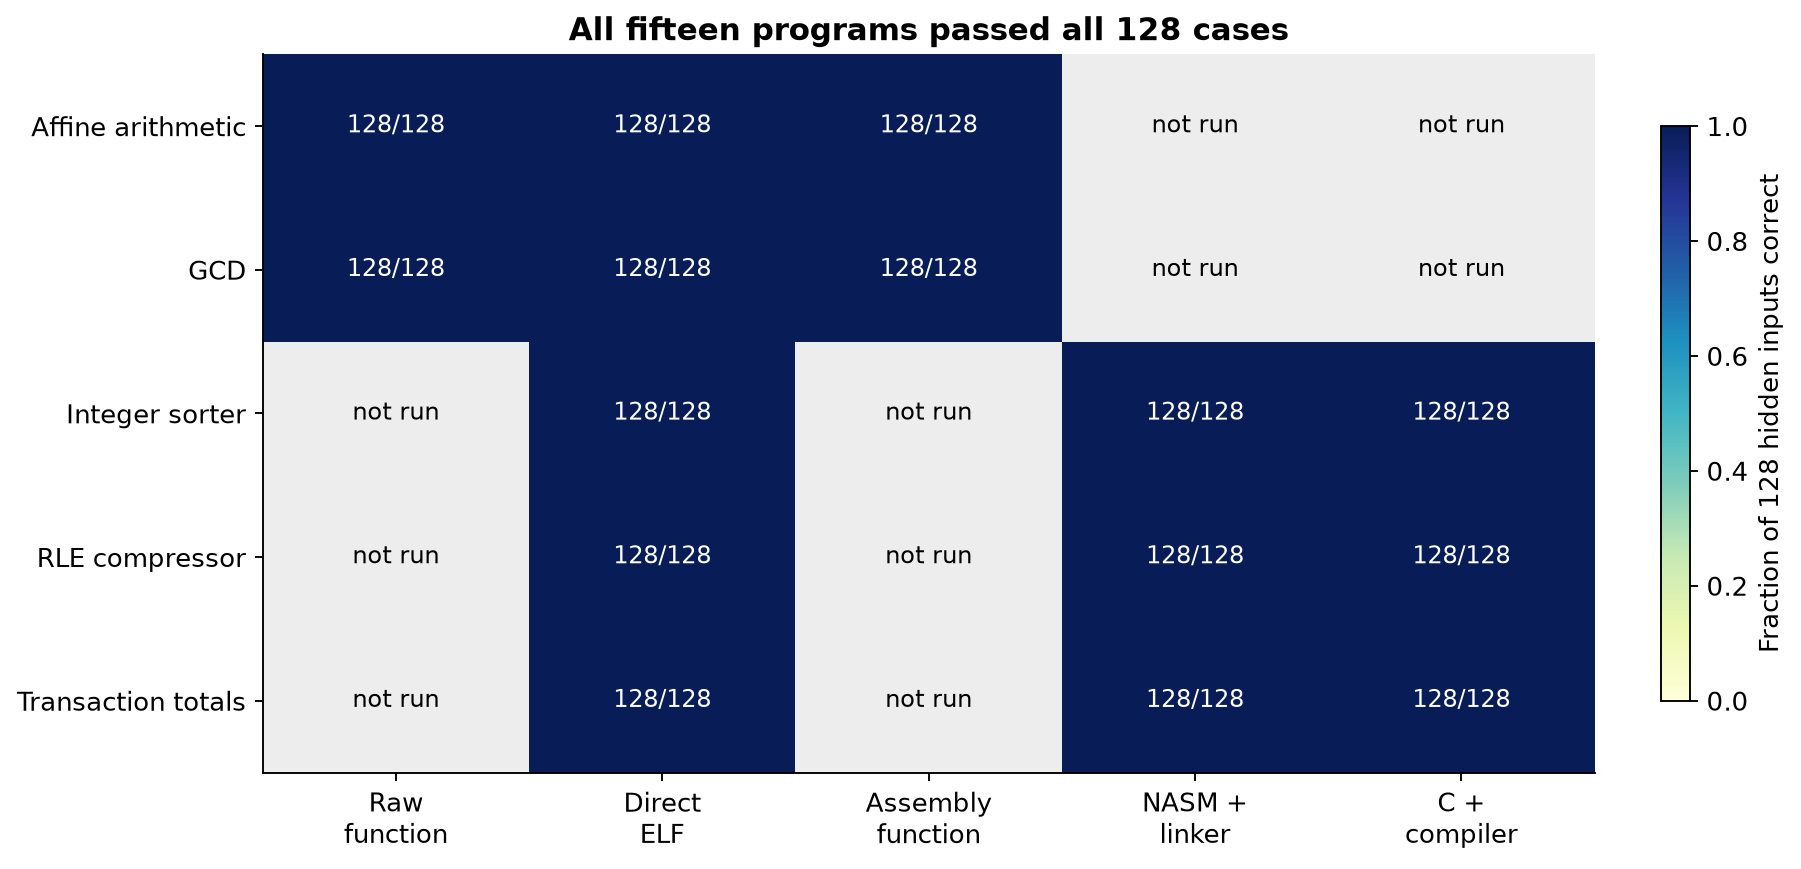

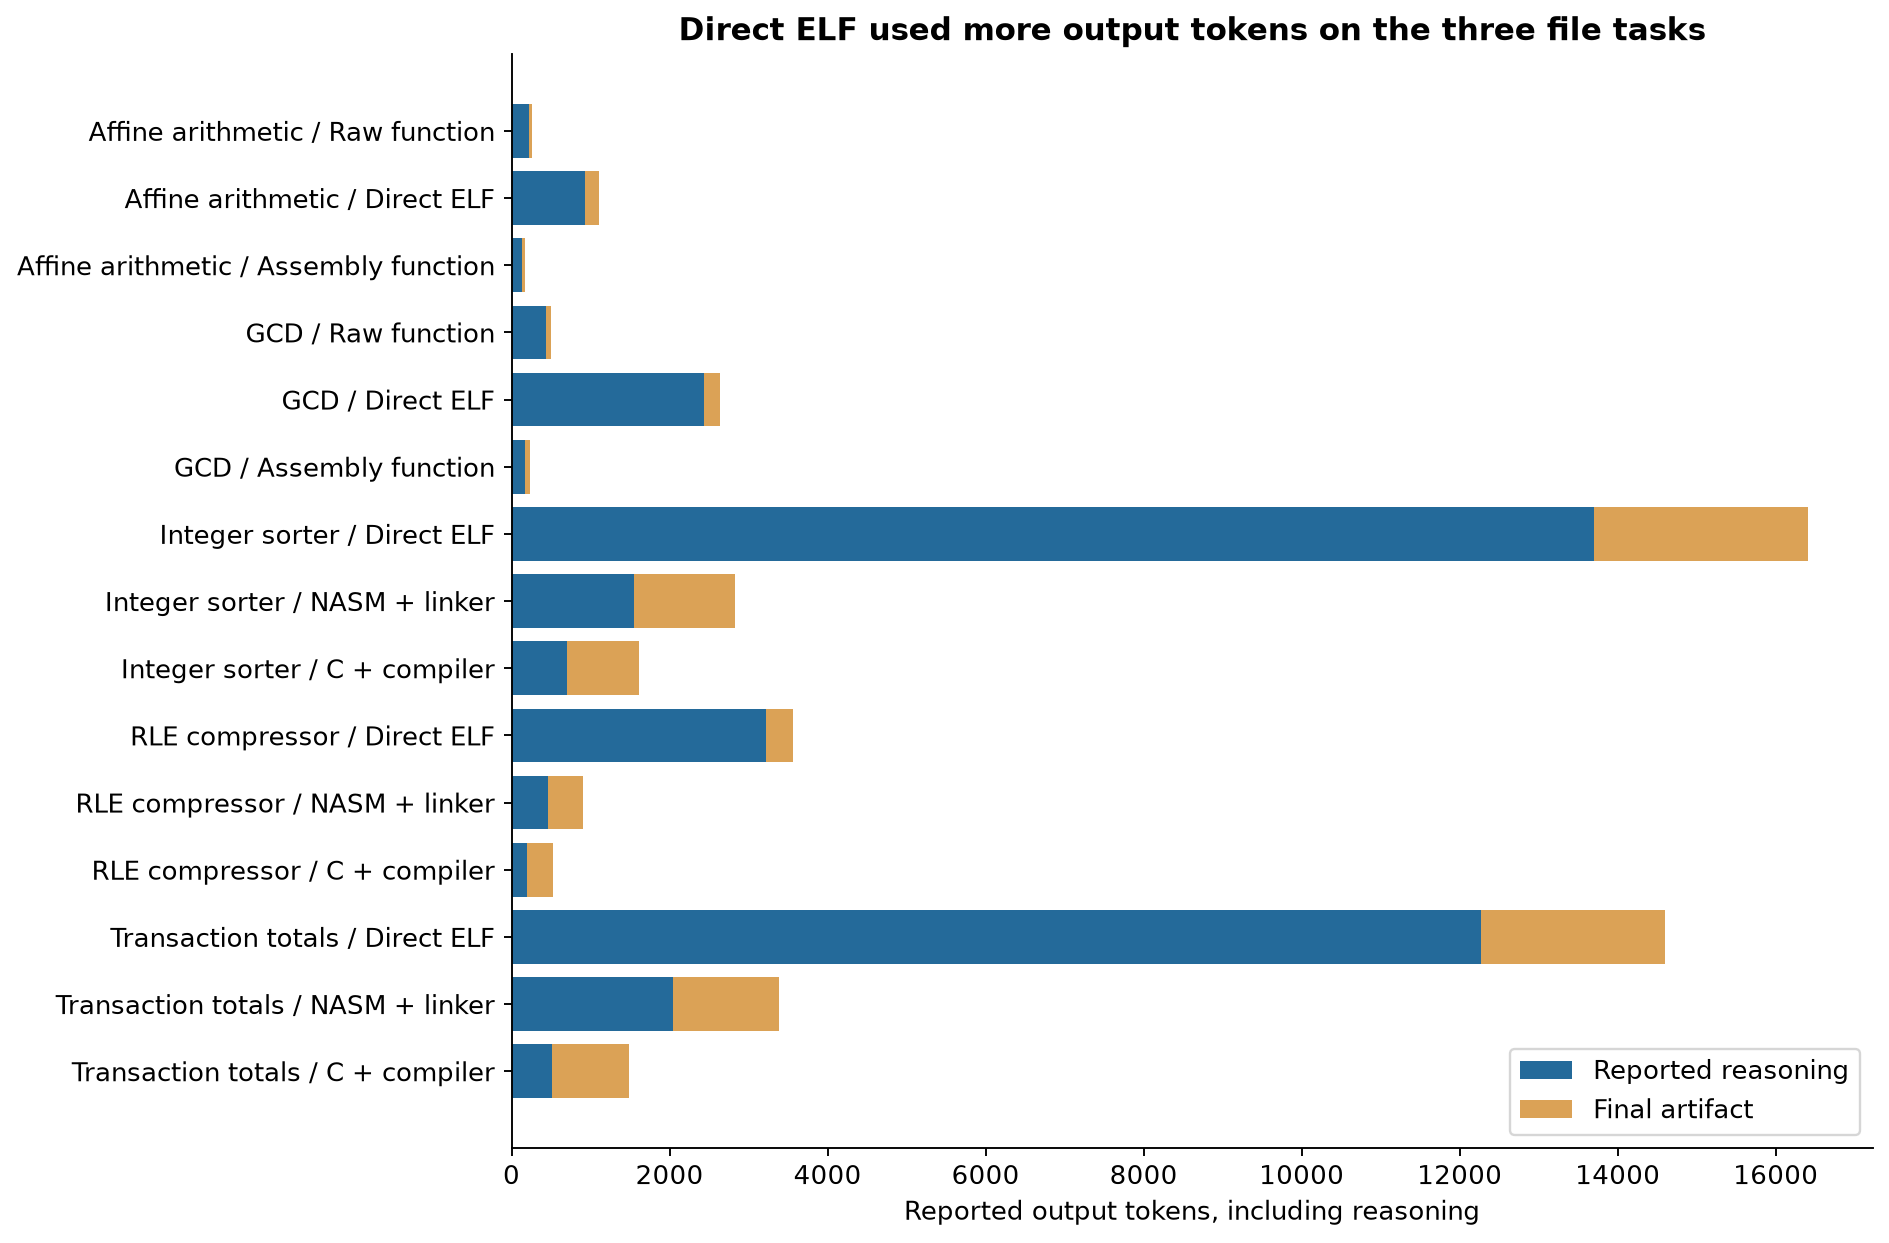

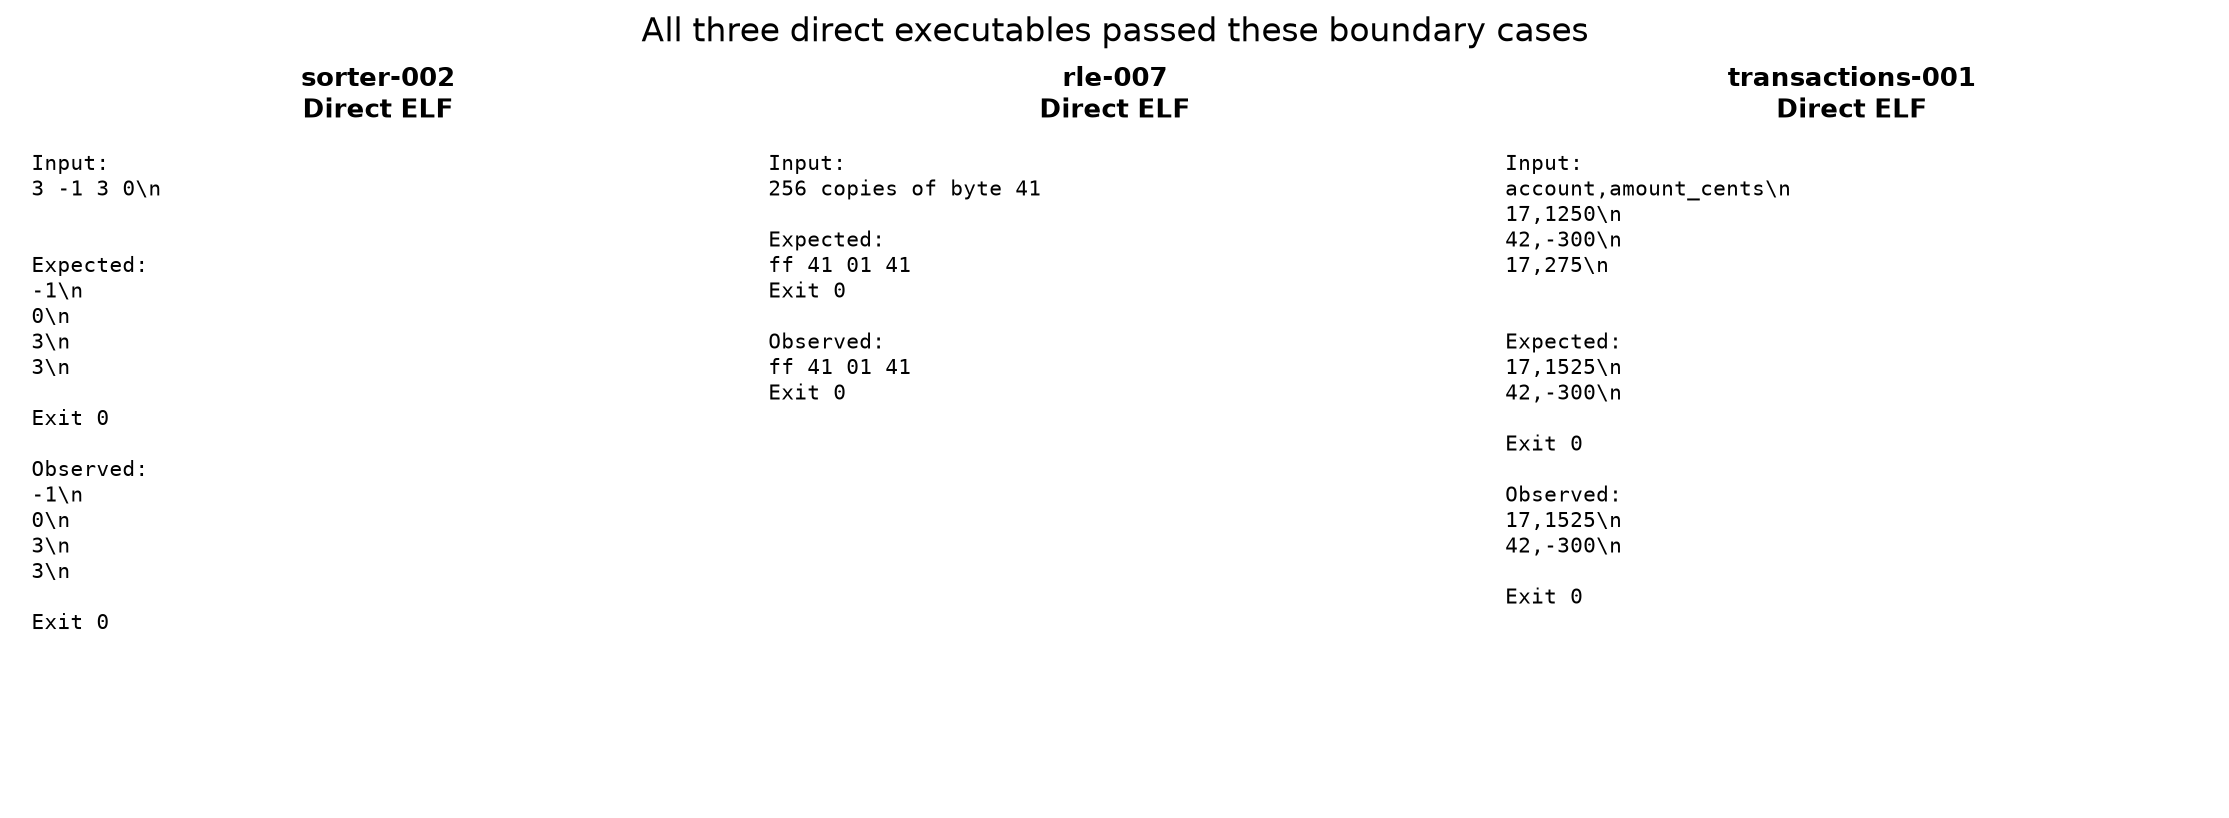

{
  "calls": 15,
  "programs_passed": 15,
  "file_programs_passed": 9,
  "correct_inputs": 1920,
  "planned_comparisons": 1920,
  "input_tokens": 109522,
  "cached_input_tokens": 12032,
  "output_tokens": 50189,
  "reasoning_output_tokens": 38965,
  "usage_missing_calls": 0,
  "api_equivalent_usd": 0.6980732,
  "actual_invoice_usd": null,
  "observed_tool_calls": 0,
  "artifact_output_tokens": 11224
}
Fresh model spend on replay: US$0. Recorded standard API equivalent: US$0.698073; actual subscription invoice unavailable.


In [7]:

NUMERIC_RESULTS = RESULTS.to_dict('records')
ALL_RESULTS = NUMERIC_RESULTS + STREAM_RESULTS
ALL_CASE_RESULTS = CASE_RESULTS + STREAM_CASE_RESULTS
ALL_CACHES = CACHE_ROWS + STREAM_CACHE_ROWS
ALL = pd.DataFrame(ALL_RESULTS)
save(DATA / 'results.json', ALL_RESULTS)
save(DATA / 'case_results.json', ALL_CASE_RESULTS)
ALL.to_csv(DATA / 'results.csv', index=False)
display(ALL[['task','format','readable','correct_inputs','runtime_errors','bytes','output_tokens','reasoning_output_tokens','api_equivalent_usd']])

task_names={'affine':'Affine arithmetic','gcd':'GCD','sorter':'Integer sorter','rle':'RLE compressor','transactions':'Transaction totals'}
format_names={'raw_hex':'Raw function','elf_hex':'Direct ELF','assembly':'Assembly function','assembly_program':'NASM + linker','c_program':'C + compiler'}
tasks=list(task_names)
formats=list(format_names)
matrix=np.full((len(tasks),len(formats)),np.nan)
annotations={}
for r in ALL_RESULTS:
    i,j=tasks.index(r['task']),formats.index(r['format'])
    matrix[i,j]=r['correct_inputs']/r['n_inputs']
    annotations[i,j]=str(r['correct_inputs'])+'/128'+('' if r['readable'] else '\nunreadable')
cmap=plt.get_cmap('YlGnBu').copy(); cmap.set_bad('#ededed')
fig,ax=plt.subplots(figsize=(10.5,5),layout='constrained')
im=ax.imshow(matrix,vmin=0,vmax=1,cmap=cmap,aspect='auto')
ax.set(xticks=range(len(formats)),xticklabels=['Raw\nfunction','Direct\nELF','Assembly\nfunction','NASM +\nlinker','C +\ncompiler'],
       yticks=range(len(tasks)),yticklabels=[task_names[t] for t in tasks],
       title='All fifteen programs passed all 128 cases')
for i in range(len(tasks)):
    for j in range(len(formats)):
        value=matrix[i,j]
        ax.text(j,i,annotations.get((i,j),'not run'),ha='center',va='center',fontsize=10,
                color='white' if np.isfinite(value) and value>.7 else 'black')
fig.colorbar(im,ax=ax,label='Fraction of 128 hidden inputs correct',shrink=.8)
fig.savefig(FIGURES/'task_correctness.png',bbox_inches='tight'); display(Image(filename=str(FIGURES/'task_correctness.png'))); plt.close(fig)

labels=[task_names[r['task']]+' / '+format_names[r['format']] for r in ALL_RESULTS]
reason=np.array([r.get('reasoning_output_tokens') or 0 for r in ALL_RESULTS])
artifact=np.array([(r.get('output_tokens') or 0)-(r.get('reasoning_output_tokens') or 0) for r in ALL_RESULTS])
y=np.arange(len(ALL_RESULTS))
fig,ax=plt.subplots(figsize=(11,7.2),layout='constrained')
ax.barh(y,reason,color='#246a9a',label='Reported reasoning')
ax.barh(y,artifact,left=reason,color='#dba256',label='Final artifact')
ax.set(yticks=y,yticklabels=labels,xlabel='Reported output tokens, including reasoning',title='Direct ELF used more output tokens on the three file tasks')
ax.invert_yaxis(); ax.legend(loc='lower right')
fig.savefig(FIGURES/'generation_usage.png',bbox_inches='tight'); display(Image(filename=str(FIGURES/'generation_usage.png'))); plt.close(fig)

def compact(task,payload):
    if task=='rle':
        if len(payload)>20 and len(set(payload))==1: return str(len(payload))+' copies of byte '+format(payload[0],'02x')
        return payload[:28].hex(' ')+(' ...' if len(payload)>28 else '') or '(empty)'
    return payload[:100].decode('ascii','backslashreplace').replace('\n','\\n\n')+(' ...' if len(payload)>100 else '') or '(empty)'
selected=[]
for task in ['sorter','rle','transactions']:
    group=[c for c in STREAM_CASE_RESULTS if c['task']==task]
    failures=sorted([c for c in group if not c['correct']],key=lambda c:(c['format']!='elf_hex',c['id']))
    preferred={'sorter':'sorter-002','rle':'rle-007','transactions':'transactions-001'}[task]
    selected.append(failures[0] if failures else next(c for c in group if c['format']=='elf_hex' and c['id']==preferred))
import textwrap
fig,axes=plt.subplots(1,3,figsize=(13,4.7),layout='constrained')
for ax,c in zip(axes,selected):
    ax.axis('off')
    inp=compact(c['task'],base64.b64decode(c['input_b64']))
    expected=compact(c['task'],base64.b64decode(c['expected_b64']))
    observed=compact(c['task'],base64.b64decode(c['observed_b64'])) if c['readable'] else 'Unreadable/build/load failure'
    body='Input:\n'+inp+'\n\nExpected:\n'+expected+'\nExit '+str(c['expected_exit'])+'\n\nObserved:\n'+observed+'\nExit '+str(c['observed_exit'])
    if c['execution_error']: body+='\n'+c['execution_error']
    body='\n'.join(textwrap.fill(line,36) for line in body.splitlines())
    ax.set_title(c['id']+'\n'+format_names[c['format']],fontsize=11)
    ax.text(.02,.97,body,va='top',fontfamily='monospace',fontsize=9,transform=ax.transAxes)
fig.suptitle('All three direct executables passed these boundary cases',fontsize=14)
fig.savefig(FIGURES/'case_panels.png',bbox_inches='tight'); display(Image(filename=str(FIGURES/'case_panels.png'))); plt.close(fig)

usage={'calls':len(ALL_CACHES),'programs_passed':sum(r['program_pass'] for r in ALL_RESULTS),
       'file_programs_passed':sum(r['program_pass'] for r in STREAM_RESULTS),
       'correct_inputs':sum(r['correct_inputs'] for r in ALL_RESULTS),
       'planned_comparisons':sum(r['n_inputs'] for r in ALL_RESULTS),
       'input_tokens':sum(c['usage'].get('input_tokens',0) for c in ALL_CACHES),
       'cached_input_tokens':sum(c['usage'].get('cached_input_tokens',0) for c in ALL_CACHES),
       'output_tokens':sum(c['usage'].get('output_tokens',0) for c in ALL_CACHES),
       'reasoning_output_tokens':sum(c['usage'].get('reasoning_output_tokens',0) for c in ALL_CACHES),
       'usage_missing_calls':sum(not c['usage'] for c in ALL_CACHES),
       'api_equivalent_usd':sum(c['api_equivalent_usd'] for c in ALL_CACHES),'actual_invoice_usd':None,
       'observed_tool_calls':sum(len(c['tool_events']) for c in ALL_CACHES)}
usage['artifact_output_tokens']=usage['output_tokens']-usage['reasoning_output_tokens']
save(DATA/'usage_summary.json',usage)
print(json.dumps(usage,indent=2))
print('Fresh model spend on replay: US$0. Recorded standard API equivalent: US$'+format(usage['api_equivalent_usd'],'.6f')+'; actual subscription invoice unavailable.')


<a id="5-correctness-across-tasks"></a>

## 5. Correctness across tasks

Read the heatmap by row. Every filled cell represents one generated program tested on 128 cases, and its annotation gives the number of correct cases. Grey cells marked “not run” are deliberately absent conditions. Numerical functions and full programs have different columns, so the small function results cannot be mistaken for complete-file controls. Colour encodes the fraction correct; labels give the exact counts without relying on colour.

![Exact hidden-case scores for fifteen programs across five tasks, with callable functions separated from complete executables.](figures/task_correctness.png)

| Task | Route | Bytes | Cases correct | Artifact stage | Execution failures | Wrong outputs |
|---|---|---|---|---|---|---|
| Affine arithmetic | Raw function | 14 | 128/128 | readable | 0 | 0 |
| Affine arithmetic | Direct ELF | 192 | 128/128 | readable | 0 | 0 |
| Affine arithmetic | Assembly function | 14 | 128/128 | readable | 0 | 0 |
| GCD | Raw function | 28 | 128/128 | readable | 0 | 0 |
| GCD | Direct ELF | 224 | 128/128 | readable | 0 | 0 |
| GCD | Assembly function | 25 | 128/128 | readable | 0 | 0 |
| Integer sorter | Direct ELF | 1348 | 128/128 | readable | 0 | 0 |
| Integer sorter | NASM + linker | 9920 | 128/128 | readable | 0 | 0 |
| Integer sorter | C + compiler | 16016 | 128/128 | readable | 0 | 0 |
| Run-length compressor | Direct ELF | 296 | 128/128 | readable | 0 | 0 |
| Run-length compressor | NASM + linker | 5232 | 128/128 | readable | 0 | 0 |
| Run-length compressor | C + compiler | 15888 | 128/128 | readable | 0 | 0 |
| Transaction totals | Direct ELF | 1152 | 128/128 | readable | 0 | 0 |
| Transaction totals | NASM + linker | 10144 | 128/128 | readable | 0 | 0 |
| Transaction totals | C + compiler | 16048 | 128/128 | readable | 0 | 0 |


Across all tasks, 15/15 programs passed all 128 cases. The matched file-processing comparison gives 9/9 passing programs. The original numerical conditions remain six of six, a ceiling on which no case separates the routes. A program that passes most files still fails the primary all-case score. This strict rule matters for a tool that could silently mishandle a malformed record or corrupt one unusually long run.

Integer sorter: Direct ELF answers 128/128 correctly and passes the whole task; NASM + linker answers 128/128 correctly and passes the whole task; C + compiler answers 128/128 correctly and passes the whole task.

Run-length compressor: Direct ELF answers 128/128 correctly and passes the whole task; NASM + linker answers 128/128 correctly and passes the whole task; C + compiler answers 128/128 correctly and passes the whole task.

Transaction totals: Direct ELF answers 128/128 correctly and passes the whole task; NASM + linker answers 128/128 correctly and passes the whole task; C + compiler answers 128/128 correctly and passes the whole task.

Artifact stage distinguishes response, build and loader failures. Execution failures are crashes or timeouts. Wrong outputs include stdout, stderr or exit-status mismatches after a completed run. None occurred here; the categories remain in the saved scores so future failures can be interpreted correctly.

The valid/malformed table makes a second distinction. Ordinary successful inputs and requested error handling both count in the complete program contract. RLE has no malformed inputs within the permitted size range; every byte value is allowed.

| Task | Route | Valid files correct | Malformed files correct |
|---|---|---|---|
| Integer sorter | Direct ELF | 112/112 | 16/16 |
| Integer sorter | NASM + linker | 112/112 | 16/16 |
| Integer sorter | C + compiler | 112/112 | 16/16 |
| Run-length compressor | Direct ELF | 128/128 | not applicable |
| Run-length compressor | NASM + linker | 128/128 | not applicable |
| Run-length compressor | C + compiler | 128/128 | not applicable |
| Transaction totals | Direct ELF | 112/112 | 16/16 |
| Transaction totals | NASM + linker | 112/112 | 16/16 |
| Transaction totals | C + compiler | 112/112 | 16/16 |


The table prevents a high aggregate score from hiding an error path. Each text program has 112 valid files and 16 malformed files, so a program that ignores every invalid case can still answer 87.5% of its files correctly. That would be inadequate for the specified tool. Conversely, a program that returns `ERR` for every input would pass those 16 error cases without doing the main task at all. The full-case score rejects both behaviours.

File sizes are descriptive. C can include runtime startup and dynamic-library references that handwritten ELF files do not. NASM/ld chooses a normal linked layout rather than the compact single-segment layout used by a direct response. Neither smaller files nor lower generation time establishes faster execution. This study measures generation usage and correctness, with no benchmark of the programs' speed.

<a id="6-token-usage-and-cost"></a>

## 6. Token usage and cost

Output usage has two parts: the returned artifact text and reported reasoning. The CLI exposes total output tokens and a reasoning subset. Subtracting that subset gives final-artifact tokens; adding it to output again would double-count it. The chart stacks these two parts for each response. Labels name the task and route, and the horizontal axis counts output tokens. A missing usage record is marked as unknown rather than treated as zero generated work.

![Reported output tokens separated into reasoning and final-artifact tokens for each generated program.](figures/generation_usage.png)

| Task | Route | Input | Cached input | Output | Reasoning subset | Seconds | API equivalent USD |
|---|---|---|---|---|---|---|---|
| Affine arithmetic | Raw function | 7177 | 0 | 254 | 217 | 9.3 | 0.016894 |
| Affine arithmetic | Direct ELF | 7277 | 0 | 1112 | 935 | 26.1 | 0.025674 |
| Affine arithmetic | Assembly function | 7184 | 0 | 168 | 128 | 8.7 | 0.016048 |
| GCD | Raw function | 7194 | 0 | 496 | 435 | 14.4 | 0.019348 |
| GCD | Direct ELF | 7294 | 6016 | 2639 | 2430 | 56.3 | 0.029548 |
| GCD | Assembly function | 7201 | 0 | 234 | 166 | 7.8 | 0.016742 |
| Integer sorter | Direct ELF | 7394 | 0 | 16408 | 13704 | 333.9 | 0.178868 |
| Integer sorter | NASM + linker | 7350 | 0 | 2829 | 1552 | 70.9 | 0.042990 |
| Integer sorter | C + compiler | 7313 | 0 | 1613 | 700 | 36.0 | 0.030756 |
| Run-length compressor | Direct ELF | 7355 | 0 | 3557 | 3218 | 79.7 | 0.050280 |
| Run-length compressor | NASM + linker | 7311 | 0 | 903 | 456 | 25.3 | 0.023652 |
| Run-length compressor | C + compiler | 7274 | 6016 | 520 | 194 | 14.2 | 0.008318 |
| Transaction totals | Direct ELF | 7441 | 0 | 14592 | 12275 | 295.7 | 0.160802 |
| Transaction totals | NASM + linker | 7397 | 0 | 3382 | 2039 | 71.2 | 0.048614 |
| Transaction totals | C + compiler | 7360 | 0 | 1482 | 516 | 35.4 | 0.029540 |


The saved calls report 109,522 input tokens and 50,189 output tokens, of which 38,965 are reasoning. The standard API equivalent for reported usage is US$0.698073. Usage is available for every call. The API equivalent is calculated at US$2 per million uncached input tokens, US$0.10 per million cached input tokens and US$10 per million output tokens. It is not a subscription invoice. [Published model rates](https://developers.openai.com/api/docs/models/gpt-6.1-sol).

The direct sorter alone used 16,408 output tokens, including 13,704 reasoning tokens, and took 333.9 seconds. Its NASM counterpart used 2,829 tokens and its C counterpart 1,613. Thus the tiny numerical programs did not forecast the encoding work of a parser and sorter. This is one observed generation per route, with the same sorter contract; it does not establish a fixed ratio or a per-byte cost law. Generation time includes service and CLI overhead and is unrelated to native execution speed.

The first numerical artifacts had only 4,903 total output tokens across six calls. Larger program layout can require more reasoning as well as more artifact text, so scaling a budget from returned byte count alone is unreliable. The larger-task measurements are useful evidence for planning another sample at similar complexity, while their one-attempt design cannot estimate a distribution of usage or a worst-case budget.

Input usage includes mandatory CLI context beyond the short task specification. Supported feature disables reduce optional context and prevent tool use, but do not remove all platform instructions. Provider cache reads are reported separately and priced accordingly. Actual subscription quota conversion, electricity and local computing cost were not measured. Replay uses the saved responses and incurs no fresh model spend.

<a id="7-boundary-cases-and-errors"></a>

## 7. Boundary cases and errors

No failure or disagreement was observed on the 1,920 comparisons. Five named file cases below show planned contract boundaries rather than invented errors. Stable IDs connect them to the saved bytes. Each input and expected answer is shared across routes, observed outputs remain unedited, and excerpts are labelled.

### Sorting and duplicate retention

Measured case `sorter-002` is in the `boundary` group. The input has a negative value, a zero and a repeated value. The correct output retains both copies of 3. This checks the actual ordering and file formatting together.

Input:

```text
3 -1 3 0

```

Expected output (9 bytes), with exit 0 and empty stderr:

```text
-1
0
3
3

```

| Route | Observed stdout | Exit | Outcome |
|---|---|---|---|
| Direct ELF | -1\n0\n3\n3\n | 0 | correct |
| NASM + linker | -1\n0\n3\n3\n | 0 | correct |
| C + compiler | -1\n0\n3\n3\n | 0 | correct |

This case passed in 3/3 routes.

Within this planned input group, the correct-file counts are Direct ELF 16/16, NASM + linker 16/16, C + compiler 16/16.

### Signed integer limits

Measured case `sorter-003` is in the `boundary` group. The smallest and largest signed 32-bit integers exercise both comparison and decimal output at the domain limits. The parser must accept these endpoints and reject values just outside them.

Input:

```text
-2147483648 2147483647 0

```

Expected output (25 bytes), with exit 0 and empty stderr:

```text
-2147483648
0
2147483647

```

| Route | Observed stdout | Exit | Outcome |
|---|---|---|---|
| Direct ELF | -2147483648\n0\n2147483647\n | 0 | correct |
| NASM + linker | -2147483648\n0\n2147483647\n | 0 | correct |
| C + compiler | -2147483648\n0\n2147483647\n | 0 | correct |

This case passed in 3/3 routes.

Within this planned input group, the correct-file counts are Direct ELF 16/16, NASM + linker 16/16, C + compiler 16/16.

### A run crossing the count-byte limit

Measured case `rle-007` is in the `boundary` group. A single count byte holds at most 255, so a run of 256 A bytes must become two pairs, ff 41 and 01 41. A wrapped count of zero or a missing final byte would fail exact output and decompression.

Input:

```text
256 copies of byte 41
```

Expected output (4 bytes), with exit 0 and empty stderr:

```text
ff 41 01 41
```

| Route | Observed stdout | Exit | Outcome |
|---|---|---|---|
| Direct ELF | ff 41 01 41 | 0 | correct |
| NASM + linker | ff 41 01 41 | 0 | correct |
| C + compiler | ff 41 01 41 | 0 | correct |

This case passed in 3/3 routes.

Within this planned input group, the correct-file counts are Direct ELF 16/16, NASM + linker 16/16, C + compiler 16/16.

### Combining repeated accounts

Measured case `transactions-001` is in the `boundary` group. Account 17 occurs twice and must total 1525 cents. Account 42 must still appear with minus 300 cents. The output is sorted by account ID, not by input order or amount.

Input:

```text
account,amount_cents
17,1250
42,-300
17,275

```

Expected output (16 bytes), with exit 0 and empty stderr:

```text
17,1525
42,-300

```

| Route | Observed stdout | Exit | Outcome |
|---|---|---|---|
| Direct ELF | 17,1525\n42,-300\n | 0 | correct |
| NASM + linker | 17,1525\n42,-300\n | 0 | correct |
| C + compiler | 17,1525\n42,-300\n | 0 | correct |

This case passed in 3/3 routes.

Within this planned input group, the correct-file counts are Direct ELF 16/16, NASM + linker 16/16, C + compiler 16/16.

### A valid row followed by a malformed row

Measured case `transactions-031` is in the `malformed` group. The first record is valid, but a later amount is not an integer. The whole file must return ERR and exit 2 without leaking partial totals. This checks when the program commits output, not just whether it can add numbers.

Input:

```text
account,amount_cents
1,2
2,bad

```

Expected output (4 bytes), with exit 2 and empty stderr:

```text
ERR

```

| Route | Observed stdout | Exit | Outcome |
|---|---|---|---|
| Direct ELF | ERR\n | 2 | correct |
| NASM + linker | ERR\n | 2 | correct |
| C + compiler | ERR\n | 2 | correct |

This case passed in 3/3 routes.

Within this planned input group, the correct-file counts are Direct ELF 16/16, NASM + linker 16/16, C + compiler 16/16.

![Three direct executable successes showing the input, expected output and matching returned result.](figures/case_panels.png)

The panels show three planned boundary cases because no failures occurred: duplicate retention in sorting, a run crossing 255 bytes, and repeated accounts in a totals file. Each gives the measured ID, direct-byte route, expected and observed outputs. The tables above give the corresponding controls and group counts.

The numerical function example in section 4 remains an end-to-end success: `affine-004` returns 344 from inputs 6 and 9, with all 14 returned bytes shown beside their decoded instructions. The numerical GCD tests also include zero and full-width unsigned values. Those successes locate the simpler end of the tested capability. They do not explain a file-processing failure by themselves; any claim about a broken branch, parser state or address requires inspection of that particular artifact.

<a id="8-what-this-result-supports"></a>

## 8. What this result supports

The evidence now covers five tasks with different demands. The numerical artifacts establish correct small instruction sequences and loadable complete files. The three file tools test parsing, arrays, variable output length and state across records under a matched external contract. The observed answer is 9/9 fully correct file-program candidates and 15/15 fully correct artifacts overall. These are claims about the saved programs, whose exact outputs can be reproduced from the caches.

One first attempt per slot does not measure how often a route will work. There are only three selected file-processing tasks, and a model can vary between generations. Running 128 cases checks an individual candidate more thoroughly, but does not create 128 independent generation trials. The task set was chosen to add difficulties after the numerical ceiling, so it is exploratory evidence about those difficulties, not a random benchmark of software engineering.

The three whole-program routes have the same permitted input and required output, but different assistance. C can call libc; assembly receives an encoder and linker; direct bytes receive neither. That comparison is relevant to someone choosing a workflow, while it does not isolate a single cognitive burden. A failure in direct output may concern algorithm choice, parsing, register use, instruction encoding or executable layout. Aggregate scores alone do not identify which one caused it.

Every task is bounded. Inputs fit within 4096 bytes, arrays have at most 128 items, and account IDs fit a 64-entry table. The tools do not implement general CSV quoting, arbitrary-size files, streaming pipes, a persistent database, concurrency, a user interface or recovery from operating-system failures. Their contracts are useful probes, but these omissions limit how far any success can be carried into a production application.

Direct requests provide an architecture, syscall identifiers and practical ELF guidance. They contain no completed header bytes, source implementation or hidden expected answers. The test therefore concerns implementing a precisely specified program with a known interface. It cannot determine whether the model internally imagined source or assembly before returning bytes; only external tool use and returned artifacts are observed.

The fixed model ID does not expose an immutable weight revision, so fresh generations may change; cached replay preserves the evidence. New input instances prevent lookup of this test set, while the familiar algorithms may occur in training.

There is no compiler-efficiency finding. Native running time, throughput and energy were not benchmarked. Complete-file byte counts include different startup, linking and runtime choices. A compact handwritten ELF and a dynamically linked C program do not have equivalent file-layout overhead. The study reports generation cost and correctness rather than interpreting smaller binaries as faster or better software.

The numerical scorer gained register and loader controls after its initial results; all six scores stayed unchanged. File contracts and controls were fixed before generation, and no response received repair feedback. [Protocol history](data/PROTOCOL.md), [file-task protocol](data/streams_v2/PROTOCOL.md).

<a id="9-reproduction-and-saved-evidence"></a>

## 9. Reproduction and saved evidence

The [executed notebook](43_direct_binary_pilot.ipynb) contains all task generators, request builders, CLI isolation settings, parsers, native runners, CPU-emulation code, scoring and chart helpers. It imports no helper code from the repository. Every model response is saved with its full request, settings, raw CLI events, timestamps and usage. Default execution replays those responses without any fresh model calls.

Install [requirements.txt](requirements.txt) and have a local Linux Docker engine. The numerical executables use the original pinned Python image. The file tools use the compiler image recorded in [toolchain.json](data/streams_v2/toolchain.json), which contains GCC 14.2.0, NASM 2.16.03 and GNU ld 2.44. The recorded image ID pins the environment actually used. Its Dockerfile pins the base digest but does not use a historical package repository, so a later rebuild may differ and must be recorded explicitly.

```powershell
cd notebooks/43-direct-binary-pilot
python -m pip install -r requirements.txt
docker build -t experiment43-toolchain:streams-v2 data/streams_v2/toolchain
python -m nbconvert --to notebook --execute --inplace 43_direct_binary_pilot.ipynb
```

The notebook checks that the recorded toolchain image is available. If a rebuild gives another image ID, an explicit environment override may be used for an execution-environment replication, with that change recorded in the protocol. Replaying the same response bytes on a different compiler, libc or kernel is a different environment check; it does not add a model generation.

Fresh generation requires setting `DIRECT_BINARY_FRESH=1` and having missing request-cache slots. The size knobs are the numerical task count, file task count, model list, output-route list and maximum fresh calls per group. The original groups contain six and nine fixed requests respectively. Frozen request identity is checked, cache entries are reused, and no automatic retry or candidate selection occurs. Changing task prompts or models requires a new protocol entry and distinct frozen requests rather than editing an old result.

The current evidence tables are [results.json](data/results.json), [results.csv](data/results.csv), [case_results.json](data/case_results.json) and [usage_summary.json](data/usage_summary.json). Numerical requests and original artifacts remain in `data/requests.json`, `data/cache/` and `data/artifacts.json`. File inputs, requests, caches, build logs, output streams and compiled/direct hex artifacts are under [data/streams_v2](data/streams_v2/). `engine.py` is a readable snapshot of that run's evaluator; the notebook defines the same helpers internally and does not import the snapshot.

Every fresh call is sent to local Langfuse after caching when its health check and environment credentials permit it. Replay sends nothing. Trace IDs are derived from notebook identity and request hashes to permit deduplication. The original six traces recorded inclusive output usage; the current helper reports the reasoning subset separately. The immutable CLI usage fields are the source for all accounting here, with no double-counting of reasoning.

The combined collection contains fifteen unique request slots and no repair candidates. The recorded API equivalent is US$0.698073 for available usage. All fifteen calls have reported usage. Actual subscription billing is unavailable. Hash manifests normalise Windows CRLF to LF so frozen inputs and response records can be checked across Git platforms. Scratch native jobs and HTML reading copies are ignored. No generated executable is launched directly on the Windows host.

<a id="10-future-work-and-further-reading"></a>

## 10. Future work and further reading

The links below were opened and checked on November 3, 2026 (America/Toronto). They document the interfaces and tools; measured correctness, bytes and token counts come from this study's saved responses.

### Future work

- Generate at least ten fresh candidates for every file-task route using the same fixed contracts. Measure whole-program success and the distribution of token usage. The current one-attempt design and its 9/9 passing file programs cannot estimate repeatability.
- Add a key-value command processor or a small expression evaluator with parentheses. Measure state transitions, parsing failures and exact error handling. The current bounded sorter, compressor and totals table cover only a few interacting components, while the numerical tasks already sit at a ceiling.
- Compare untouched first attempts with a fixed one-diagnostic repair allowance, retaining both results and all costs. Measure how many build, loader and execution failures can be recovered. No present artifact received feedback, so this study cannot tell whether observed problems are cheap to repair.
- Match runtime and linking choices across source and direct-byte routes, then benchmark only candidates proven correct. Measure code size and native throughput on a fixed platform. Current file lengths include different library and linker overhead and cannot answer compiler-efficiency claims.
- Repeat selected tasks on another architecture and at another reasoning effort. Measure instruction/layout failures and complete-contract success per token. The direct sorter's 16,408 output tokens and the smaller compressor request show that one tiny arithmetic sample cannot forecast generation usage at another complexity.

### Further reading

- [ELF program loading](https://gabi.xinuos.com/elf/07-pheader.html) (Xinuos, ELF Object File Format 4.3 draft, accessed 2026). Explains the segment and entry information a complete executable must supply.
- [NASM output formats](https://www.nasm.us/doc/nasm09.html) (NASM contributors, accessed 2026). Describes assembler output formats used to turn the source control into ELF object code.
- [GCC optimisation options](https://gcc.gnu.org/onlinedocs/gcc/Optimize-Options.html) (GNU Project, accessed 2026). Documents the compiler optimisation setting used for the C workflow.
- [GNU linker command-line options](https://sourceware.org/binutils/docs/ld/Options.html) (GNU Project, accessed 2026). Gives the linker interface used to construct the assembly executables.
- [How SQLite is tested](https://sqlite.org/testing.html) (SQLite contributors, accessed 2026). Shows why boundary inputs, malformed data and independent test machinery matter beyond a few successful examples.